# ConnectTel: Predictive Customer Churn Model

**Author:** ML Engineering Intern &nbsp;|&nbsp; **Dataset:** IBM Telco Customer Churn (7,043 customers)

---

## 1. Problem Statement

ConnectTel is losing millions in revenue every quarter to **customer churn**: subscribers cancelling to move to a competitor. Acquiring a new customer costs far more than retaining an existing one, so every churner the business can identify *before* they leave is an opportunity to save revenue.

**Business goal:** build a model that ranks current customers by their **probability of churning**, so the retention team can target the highest-risk customers with offers (discounts, upgrades, contract incentives) before they cancel.

**What success looks like**

| Requirement | How we address it |
|---|---|
| Find churners reliably | Optimise **ROC-AUC** and inspect **Recall** (share of real churners we catch) |
| Do not waste retention budget | Inspect **Precision** (share of flagged customers who really would churn) |
| Explain *why* a customer is at risk | **SHAP** explanations, global and per customer |
| Turn results into action | Business Insight Report with concrete recommendations |

> **Why not accuracy?** Only about 26% of customers churn. A model that predicts "nobody churns" is 73% accurate and completely useless.

**Notebook roadmap**
1. Problem Statement
2. Data Loading & Quality Checks
3. Exploratory Data Analysis
4. Hypothesis Testing
5. Feature Engineering
6. Encoding & Scaling
7. Model Training & Cross-Validation
8. Boosting & Hyperparameter Tuning
9. Model Interpretation with SHAP
10. Business Insight Report
11. Limitations & Next Steps

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT))
from src import data_prep as dp

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.3f}".format)

RANDOM_STATE = 42
FIG_DIR = PROJECT_ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

# Consistent colours throughout the report: blue = retained, red = churned.
STAY_COLOR, CHURN_COLOR = "#4C72B0", "#C44E52"
CHURN_PALETTE = {0: STAY_COLOR, 1: CHURN_COLOR}
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})

STATUS = {0: "Retained", 1: "Churned"}
STATUS_PALETTE = {"Retained": STAY_COLOR, "Churned": CHURN_COLOR}

_fig_counter = 0
def finish_fig(fig, slug, title, ax=None):
    # Number the figure, title it (axis title or suptitle) and export it for the report.
    global _fig_counter
    _fig_counter += 1
    if ax is not None:
        ax.set_title(f"Figure {_fig_counter}: {title}")
    else:
        fig.suptitle(f"Figure {_fig_counter}: {title}", y=1.02, fontsize=14, fontweight="bold")
    fig.savefig(FIG_DIR / f"fig{_fig_counter:02d}_{slug}.png", bbox_inches="tight", dpi=150)
    plt.show()

## 2. Data Loading & Quality Checks

In [2]:
raw = dp.load_raw()
print(f"Shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

Shape: 7,043 rows x 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.850,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.950,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.850,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.300,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.700,151.65,Yes


In [3]:
quality = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "n_unique": raw.nunique(),
    "n_missing": raw.isna().sum(),
    "n_blank_strings": raw.apply(lambda s: s.astype(str).str.strip().eq("").sum()),
})
print(f"Duplicate rows: {raw.duplicated().sum()} | Duplicate customerIDs: {raw['customerID'].duplicated().sum()}")
quality

Duplicate rows: 0 | Duplicate customerIDs: 0

,dtype,n_unique,n_missing,n_blank_strings
customerID,str,7043,0,0
gender,str,2,0,0
SeniorCitizen,int64,2,0,0
Partner,str,2,0,0
Dependents,str,2,0,0
tenure,int64,73,0,0
PhoneService,str,2,0,0
MultipleLines,str,3,0,0
InternetService,str,3,0,0
OnlineSecurity,str,3,0,0


In [4]:
blank_tc = raw[raw["TotalCharges"].str.strip() == ""]
print(f"{len(blank_tc)} customers have a blank TotalCharges. Their tenure values: {blank_tc['tenure'].unique()}")
blank_tc[["tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]]

11 customers have a blank TotalCharges. Their tenure values: [0]


,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,0,52.550,,Two year,No
753,0,20.250,,Two year,No
936,0,80.850,,Two year,No
1082,0,25.750,,Two year,No
1340,0,56.050,,Two year,No
3331,0,19.850,,Two year,No
3826,0,25.350,,Two year,No
4380,0,20.000,,Two year,No
5218,0,19.700,,One year,No
6670,0,73.350,,Two year,No


**Findings.**
- No duplicate rows or customer IDs, and no true `NaN` values.
- `TotalCharges` is stored as **text**. It has **11 blank values**, and every one belongs to a customer with `tenure = 0`, i.e. a customer who has just signed up and has not been billed yet. The correct value is therefore **0**, not the column mean.
- `SeniorCitizen` is coded 0/1 while the other yes/no columns are text. We relabel it to `No`/`Yes` for consistency.
- `customerID` is an identifier with no predictive value, so we drop it.

In [5]:
df = dp.clean(raw)
print(f"Clean shape: {df.shape} | remaining missing values: {df.isna().sum().sum()}")
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe().T

Clean shape: (7043, 20) | remaining missing values: 0


,count,mean,std,min,25%,50%,75%,max
tenure,7043.000,32.371,24.559,0.000,9.000,29.000,55.000,72.000
MonthlyCharges,7043.000,64.762,30.090,18.250,35.500,70.350,89.850,118.750
TotalCharges,7043.000,2279.734,2266.794,0.000,398.550,1394.550,3786.600,8684.800


## 3. Exploratory Data Analysis

### 3.1 Target variable

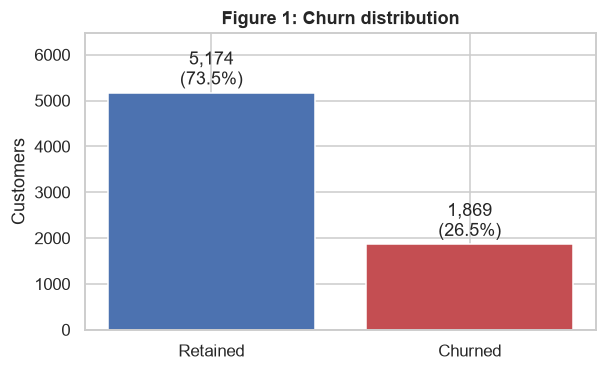

Overall churn rate: 26.5% | imbalance ratio 2.77 : 1


In [6]:
churn_counts = df["Churn"].value_counts().sort_index()
churn_rate = df["Churn"].mean()

fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar(["Retained", "Churned"], churn_counts.values, color=[STAY_COLOR, CHURN_COLOR])
for bar, n in zip(bars, churn_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n + 60, f"{n:,}\n({n / len(df):.1%})", ha="center", va="bottom")
ax.set_ylim(0, churn_counts.max() * 1.25)
ax.set_ylabel("Customers")
finish_fig(fig, "target_distribution", "Churn distribution", ax)
print(f"Overall churn rate: {churn_rate:.1%} | imbalance ratio {churn_counts[0] / churn_counts[1]:.2f} : 1")

**Figure 1.** About **26.5%** of customers churned, so the classes are imbalanced at roughly **2.8 retained customers for every churner**. This confirms that accuracy would be a misleading metric. During modelling we will use **stratified** splits so every fold keeps this ratio, focus on **ROC-AUC / Precision / Recall**, and try class weighting.

### 3.2 Numerical features

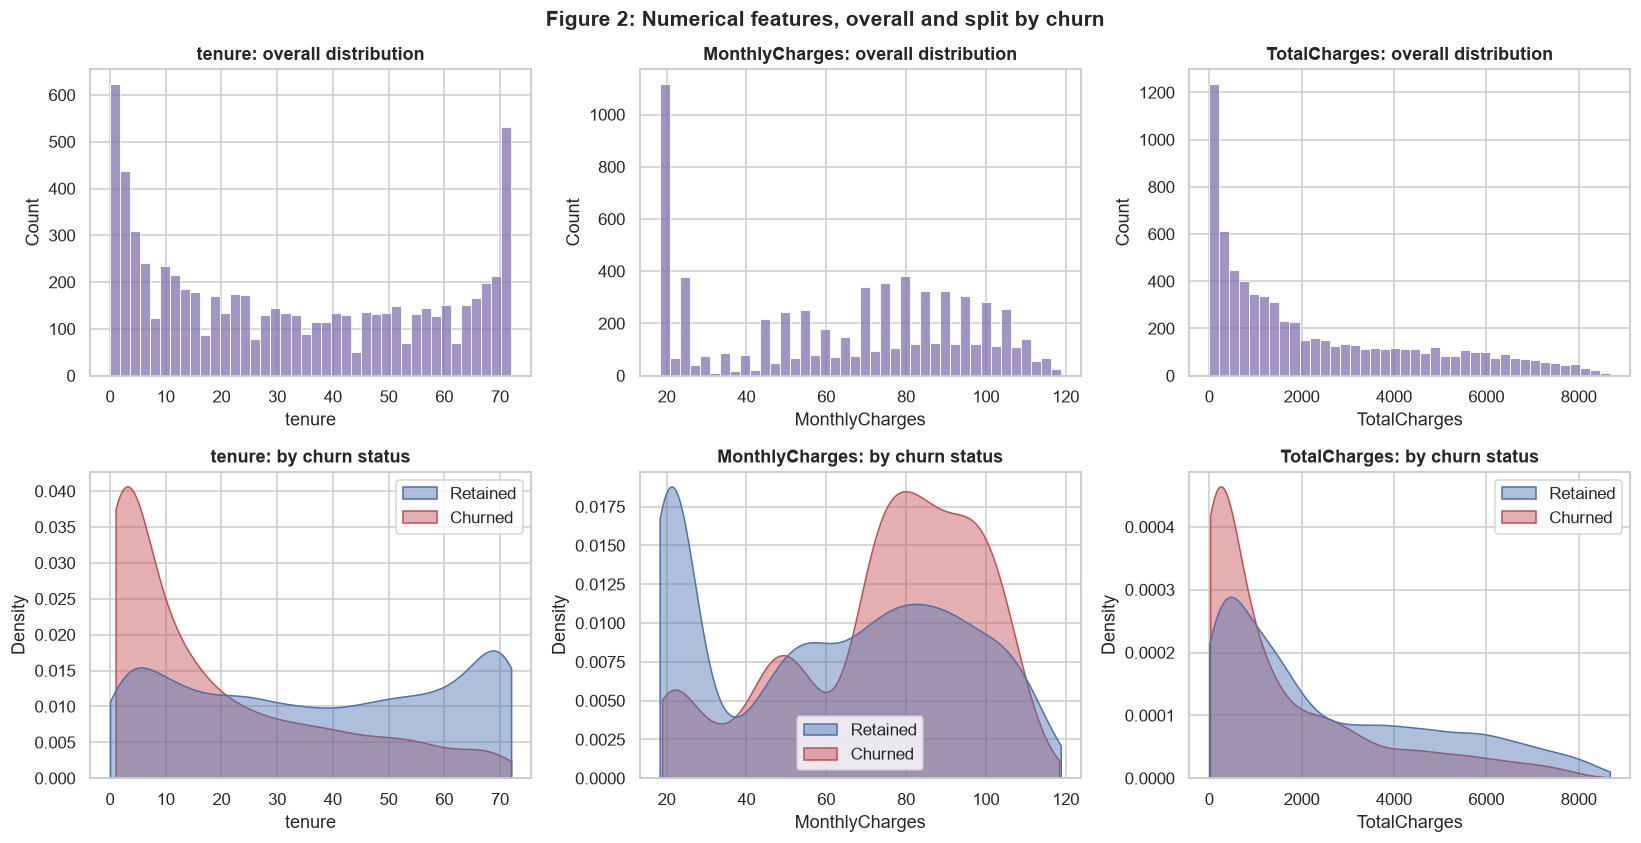

,tenure,MonthlyCharges,TotalCharges
Churn,,,
Retained (median),38.000,64.425,1679.525
Churned (median),10.000,79.650,703.550


In [7]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for i, col in enumerate(num_cols):
    sns.histplot(df[col], bins=40, ax=axes[0, i], color="#8172B2")
    axes[0, i].set_title(f"{col}: overall distribution")
    sns.kdeplot(x=df[col], hue=df["Churn"].map(STATUS), fill=True, common_norm=False, alpha=0.45,
                palette=STATUS_PALETTE, ax=axes[1, i], cut=0)
    axes[1, i].set_title(f"{col}: by churn status")
    axes[1, i].get_legend().set_title("")
fig.tight_layout()
finish_fig(fig, "numeric_distributions", "Numerical features, overall and split by churn")

df.groupby("Churn")[num_cols].median().rename(index={0: "Retained (median)", 1: "Churned (median)"})

**Figure 2. Key observations**
- **Tenure** is bimodal: there are clusters of brand-new customers and of long-term (around 72-month) loyal customers. **Churners are concentrated in the first months.** The median churner had been with ConnectTel for only **10 months**, against **38 months** for retained customers.
- **MonthlyCharges:** churners skew toward **higher bills**, with a dense cluster between \$70 and \$110 (median **\$79.65** vs **\$64.43**).
- **TotalCharges** is lower for churners. This mostly reflects tenure (they leave before accumulating charges), so it is largely redundant with tenure × monthly charges.

### 3.3 Categorical features vs churn

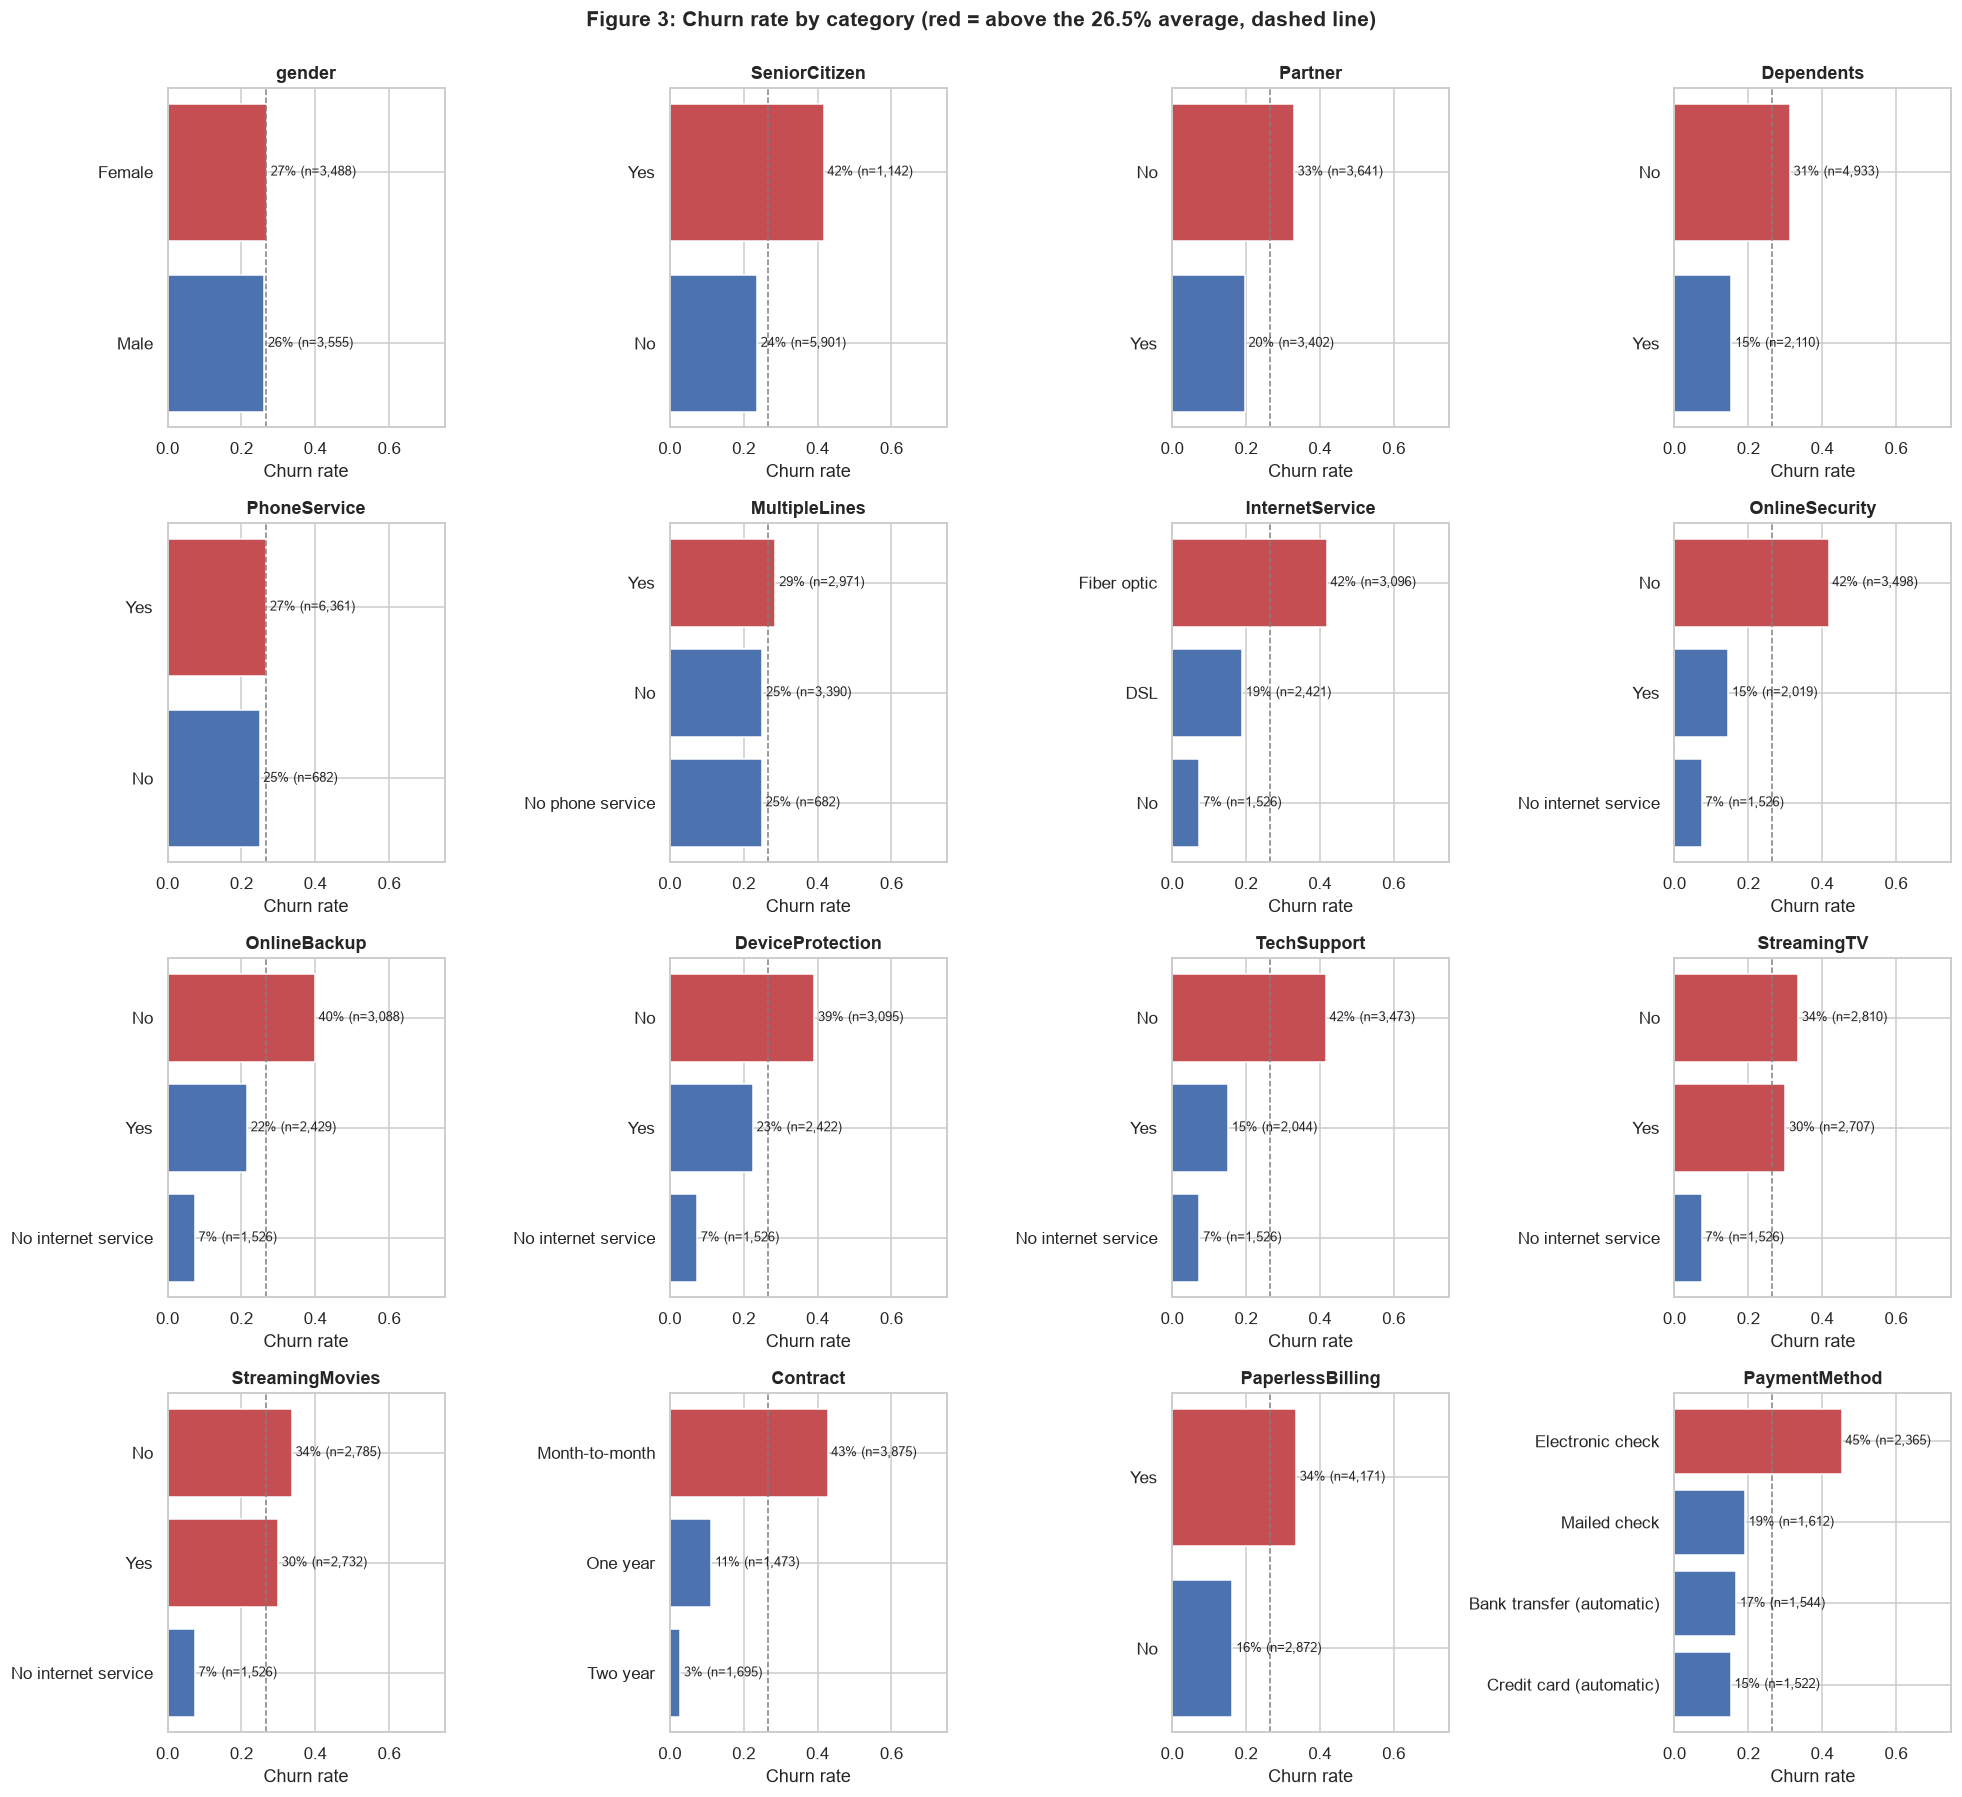

In [8]:
cat_cols = [c for c in df.columns if df[c].dtype == object or str(df[c].dtype) in ("str", "string", "category")]

def churn_rate_table(data, col):
    t = data.groupby(col)["Churn"].agg(churn_rate="mean", customers="size")
    return t.sort_values("churn_rate", ascending=False)

ncols = 4
nrows = int(np.ceil(len(cat_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4 * nrows))
for ax, col in zip(axes.flat, cat_cols):
    t = churn_rate_table(df, col)
    colors = [CHURN_COLOR if r > churn_rate else STAY_COLOR for r in t["churn_rate"]]
    ax.barh(t.index.astype(str), t["churn_rate"], color=colors)
    ax.axvline(churn_rate, ls="--", c="grey", lw=1)
    for y, (r, cnt) in enumerate(zip(t["churn_rate"], t["customers"])):
        ax.text(r + 0.01, y, f"{r:.0%} (n={cnt:,})", va="center", fontsize=8.5)
    ax.set_xlim(0, 0.75)
    ax.invert_yaxis()
    ax.set_title(col)
    ax.set_xlabel("Churn rate")
for ax in axes.flat[len(cat_cols):]:
    ax.axis("off")
fig.tight_layout()
finish_fig(fig, "categorical_churn_rates", f"Churn rate by category (red = above the {churn_rate:.1%} average, dashed line)")

**Figure 3. Key observations** (the dashed line is the 26.5% average churn rate)

| Feature | Highest-risk group | Lowest-risk group | Takeaway |
|---|---|---|---|
| **Contract** | Month-to-month **42.7%** | Two year **2.8%** | The strongest single signal. Month-to-month customers churn **15x** more than 2-year customers. |
| **InternetService** | Fiber optic **41.9%** | No internet **7.4%** | Fiber users churn **2.2x** more than DSL users (19.0%) despite the premium product. |
| **PaymentMethod** | Electronic check **45.3%** | Credit card (auto) **15.2%** | Manual payment adds friction. Automatic payers stay. |
| **OnlineSecurity / TechSupport** | "No" **~42%** | "Yes" **~15%** | Protection and support services are associated with much lower churn. |
| **SeniorCitizen** | Yes **41.7%** | No **23.6%** | Seniors are a higher-risk segment. |
| **Partner / Dependents** | No partner **33.0%**, no dependents **31.3%** | With partner **19.7%**, with dependents **15.5%** | Household ties are associated with lower churn. |
| **PaperlessBilling** | Yes **33.6%** | No **16.3%** | Likely a proxy for digitally engaged, price-comparing customers. |
| **gender / PhoneService** | ~equal | ~equal | **No meaningful difference.** These are likely weak predictors. |

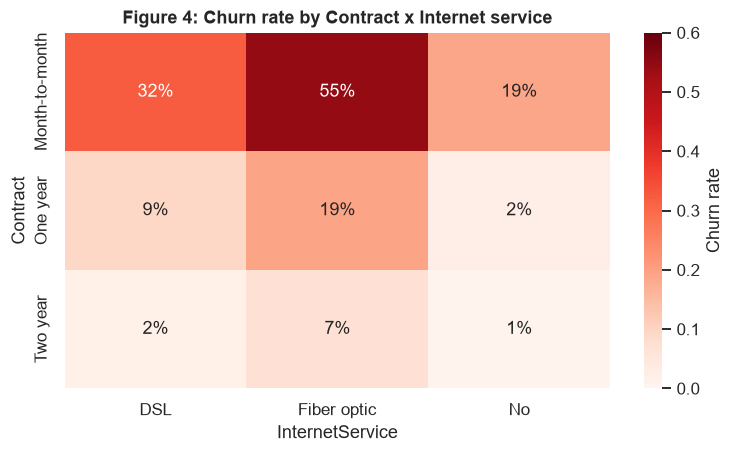

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ct = (df.groupby(["Contract", "InternetService"])["Churn"].mean().unstack()
        .reindex(["Month-to-month", "One year", "Two year"]))
sns.heatmap(ct, annot=True, fmt=".0%", cmap="Reds", vmin=0, vmax=0.6, cbar_kws={"label": "Churn rate"}, ax=ax)
finish_fig(fig, "contract_x_internet_heatmap", "Churn rate by Contract x Internet service", ax)

**Figure 4.** The combinations make the risk concentration obvious. **Month-to-month Fiber optic** customers churn at **~55%**, while customers on **two-year contracts** churn at **under 8%** whatever their internet type (fiber 7.2%, DSL 1.9%). Contract length largely *overrides* the fiber effect, which points to an intervention we will test against the model later: moving fiber customers onto longer contracts.

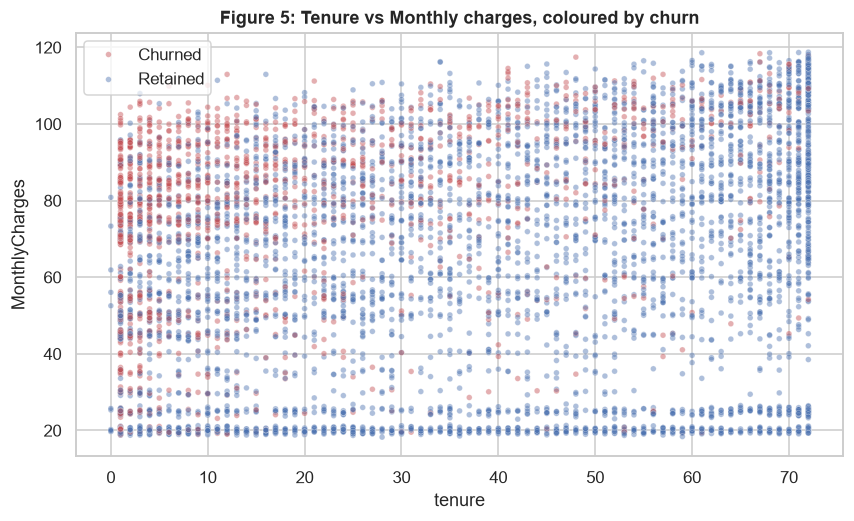

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
shuffled = df.sample(frac=1, random_state=RANDOM_STATE)  # shuffle so neither class is drawn entirely on top
sns.scatterplot(x=shuffled["tenure"], y=shuffled["MonthlyCharges"], hue=shuffled["Churn"].map(STATUS),
                palette=STATUS_PALETTE, alpha=0.45, s=14, ax=ax)
ax.get_legend().set_title("")
finish_fig(fig, "tenure_vs_monthly_charges", "Tenure vs Monthly charges, coloured by churn", ax)

**Figure 5.** Churners (red) cluster in the **top-left corner**: **short tenure and high monthly charges** (above about \$70). Long-tenure customers rarely churn whatever they pay. Early-life, high-bill customers are the clearest target segment.

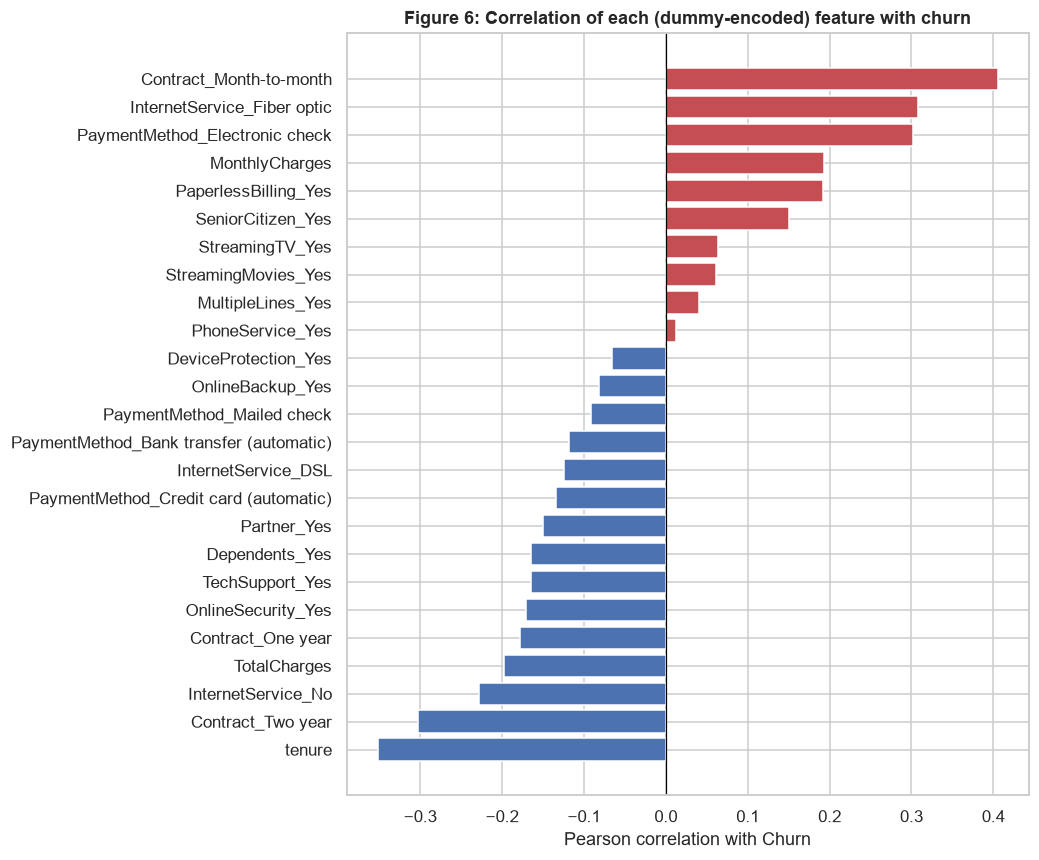

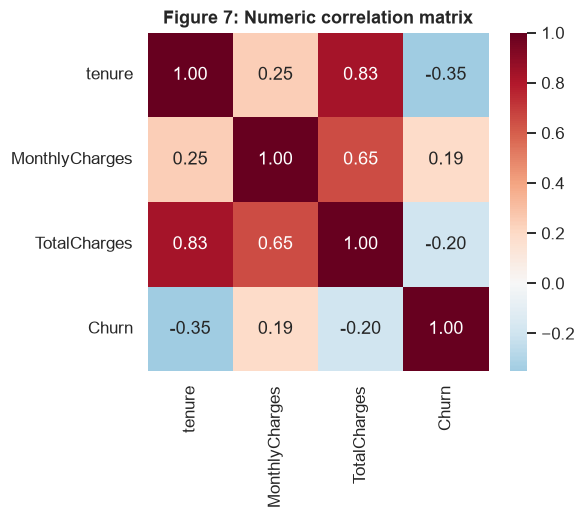

In [11]:
# Full one-hot encoding (no drop_first) so every Contract level is visible. Then remove redundant columns:
# the "No internet/phone service" levels duplicate InternetService_No / PhoneService_No, and for
# yes/no columns the "_No" dummy is just the mirror image of "_Yes".
corr_df = pd.get_dummies(df.drop(columns=["gender"]), dtype=int)
redundant = [c for c in corr_df.columns
             if c.endswith(("_No internet service", "_No phone service"))
             or (c.endswith("_No") and c[:-3] + "_Yes" in corr_df.columns)]
target_corr = corr_df.drop(columns=redundant).corr()["Churn"].drop("Churn").sort_values()

fig, ax = plt.subplots(figsize=(8, 9))
colors = [CHURN_COLOR if v > 0 else STAY_COLOR for v in target_corr]
ax.barh(target_corr.index, target_corr.values, color=colors)
ax.axvline(0, c="black", lw=0.8)
ax.set_xlabel("Pearson correlation with Churn")
finish_fig(fig, "target_correlations", "Correlation of each (dummy-encoded) feature with churn", ax)

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(df[num_cols + ["Churn"]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
finish_fig(fig, "numeric_correlation_matrix", "Numeric correlation matrix", ax)

**Figures 6 & 7.**
- **Strongest positive churn correlates** (red): month-to-month contract, fiber optic, electronic check, monthly charges, paperless billing, senior citizen.
- **Strongest negative churn correlates** (blue): tenure, two-year contracts, having no internet service, online security and tech support, and having dependents or a partner.
- `TotalCharges` is **strongly correlated with tenure (r ≈ 0.83)**. That is expected, since total ≈ tenure × monthly. Linear models may suffer from this multicollinearity, and the engineered ratio feature below helps separate the two effects.

## 4. Hypothesis Testing

We use the **Chi-square test of independence** for categorical variables, together with **Cramér's V** for effect size. With 7,000 rows even tiny differences come out "significant", so effect size matters more than the p-value. For the continuous variables we use the **Mann-Whitney U** test, which is non-parametric because the distributions are clearly not normal (Figure 2).

Significance level: α = 0.05.

In [12]:
def chi_square_test(data, col, groups=None):
    sub = data if groups is None else data[data[col].isin(groups)]
    table = pd.crosstab(sub[col], sub["Churn"])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    rates = sub.groupby(col)["Churn"].mean()
    return {"chi2": chi2, "p_value": p, "dof": dof, "cramers_v": cramers_v,
            "churn_rates": ", ".join(f"{k}: {v:.1%}" for k, v in rates.items())}

hypotheses = {
    "H1: Fiber optic users churn more than DSL users": ("InternetService", ["Fiber optic", "DSL"]),
    "H2: Having a partner reduces churn risk": ("Partner", None),
    "H3: Month-to-month contracts churn more than term contracts": ("Contract", None),
    "H4: Senior citizens churn more": ("SeniorCitizen", None),
    "Control: Gender is unrelated to churn": ("gender", None),
}
results = pd.DataFrame({h: chi_square_test(df, col, grp) for h, (col, grp) in hypotheses.items()}).T
results["reject_H0"] = results["p_value"].astype(float) < 0.05
results

,chi2,p_value,dof,cramers_v,churn_rates,reject_H0
H1: Fiber optic users churn more than DSL users,328.263,0.000,1,0.244,"DSL: 19.0%, Fiber optic: 41.9%",True
H2: Having a partner reduces churn risk,158.733,0.000,1,0.150,"No: 33.0%, Yes: 19.7%",True
H3: Month-to-month contracts churn more than term contracts,1184.597,0.000,2,0.410,"Month-to-month: 42.7%, One year: 11.3%, Two ye...",True
H4: Senior citizens churn more,159.426,0.000,1,0.150,"No: 23.6%, Yes: 41.7%",True
Control: Gender is unrelated to churn,0.484,0.487,1,0.008,"Female: 26.9%, Male: 26.2%",False


In [13]:
# Directional check for H1 and H2: one-sided two-proportion z-tests
def two_prop_ztest(data, col, group_a, group_b):
    a, b = data.loc[data[col] == group_a, "Churn"], data.loc[data[col] == group_b, "Churn"]
    p_pool = (a.sum() + b.sum()) / (len(a) + len(b))
    se = np.sqrt(p_pool * (1 - p_pool) * (1 / len(a) + 1 / len(b)))
    z = (a.mean() - b.mean()) / se
    return a.mean(), b.mean(), z, stats.norm.sf(z)  # one-sided: P(rate_a > rate_b)

for label, (col, a, b) in {"H1 Fiber > DSL": ("InternetService", "Fiber optic", "DSL"),
                           "H2 No partner > Partner": ("Partner", "No", "Yes")}.items():
    ra, rb, z, p = two_prop_ztest(df, col, a, b)
    print(f"{label:25s}: {ra:.1%} vs {rb:.1%} | relative risk {ra / rb:.2f}x | z = {z:.2f}, one-sided p = {p:.2e}")

print("\nMann-Whitney U (churned vs retained):")
for col in num_cols:
    u, p = stats.mannwhitneyu(df.loc[df.Churn == 1, col], df.loc[df.Churn == 0, col])
    print(f"  {col:15s} U = {u:,.0f}, p = {p:.2e}")

H1 Fiber > DSL           : 41.9% vs 19.0% | relative risk 2.21x | z = 18.15, one-sided p = 6.76e-74
H2 No partner > Partner  : 33.0% vs 19.7% | relative risk 1.68x | z = 12.63, one-sided p = 7.60e-37

Mann-Whitney U (churned vs retained):
  tenure          U = 2,515,538, p = 2.42e-208
  MonthlyCharges  U = 6,003,126, p = 3.31e-54
  TotalCharges    U = 3,381,224, p = 5.69e-83


### Hypothesis conclusions

| Hypothesis | Result | Interpretation |
|---|---|---|
| **H1:** Fiber optic users churn more than DSL | ✅ **Supported** (p ≪ 0.001) | Fiber churn is **41.9% vs 19.0%** for DSL, a **2.2x relative risk**. This suggests a **price/value or service-quality problem** with the fiber product. |
| **H2:** Having a partner reduces churn | ✅ **Supported** (p ≪ 0.001) | Customers without a partner churn at **33.0% vs 19.7%** (1.7x). The effect is real but **weaker** (Cramér's V ≈ 0.15) than contract or internet type. |
| **H3:** Month-to-month churns more | ✅ **Supported**, **largest effect** (V ≈ 0.41) | Contract type is the strongest categorical signal in the data. |
| **H4:** Seniors churn more | ✅ **Supported** | 41.7% vs 23.6%. |
| **Control:** Gender | ❌ **Not significant** (p ≈ 0.49) | As expected, a sanity check that the testing approach does not flag everything. |

All three numerical features also differ significantly between churners and non-churners (Mann-Whitney p ≪ 0.001).

> ⚠️ These are **associations, not causal effects**. For example, fiber customers also pay more and are more often on month-to-month contracts. The multivariate model and SHAP analysis (Phase 4) will separate these overlapping effects.

## 5. Feature Engineering

Raw columns do not directly express some behaviours we believe drive churn. We create **six** new features (the brief requires at least three):

| Feature | Definition | Rationale |
|---|---|---|
| `TotalChargesPerTenure` | `TotalCharges / tenure` (falls back to `MonthlyCharges` when tenure = 0) | Average monthly spend over the customer's lifetime. It captures price exposure independently of tenure. |
| `ServiceCount` | Number of add-on services subscribed (out of 7) | Customers using more services are more "embedded" and face higher switching costs. |
| `TenureGroup` | Tenure bucketed into 0-12m / 13-24m / 25-48m / 49-72m | Captures the non-linear "first year is the danger zone" pattern seen in Figure 2. |
| `HasProtection` | Has any of Online Security, Online Backup, Device Protection or Tech Support | Figure 3 showed protection and support services sharply lower churn. |
| `HasStreaming` | Has Streaming TV or Streaming Movies | An entertainment engagement flag. |
| `IsAutoPay` | Pays by automatic bank transfer or credit card | Electronic-check payers churn at roughly 3x the rate of auto-payers. |

In [14]:
df = dp.engineer_features(df)
new_features = ["TotalChargesPerTenure", "ServiceCount", "TenureGroup", "HasProtection", "HasStreaming", "IsAutoPay"]

# Sanity checks on the engineered features
assert df["TotalChargesPerTenure"].notna().all() and (df["TotalChargesPerTenure"] > 0).all()
assert df["ServiceCount"].between(0, len(dp.ADDON_SERVICES)).all()
assert df["TenureGroup"].isin(dp.TENURE_LABELS).all()
df[new_features + ["Churn"]].head()

,TotalChargesPerTenure,ServiceCount,TenureGroup,HasProtection,HasStreaming,IsAutoPay,Churn
0,29.850,1,0-12m,Yes,No,No,0
1,55.574,2,25-48m,Yes,No,No,0
2,54.075,2,0-12m,Yes,No,No,1
3,40.906,3,25-48m,Yes,No,Yes,0
4,75.825,0,0-12m,No,No,No,1


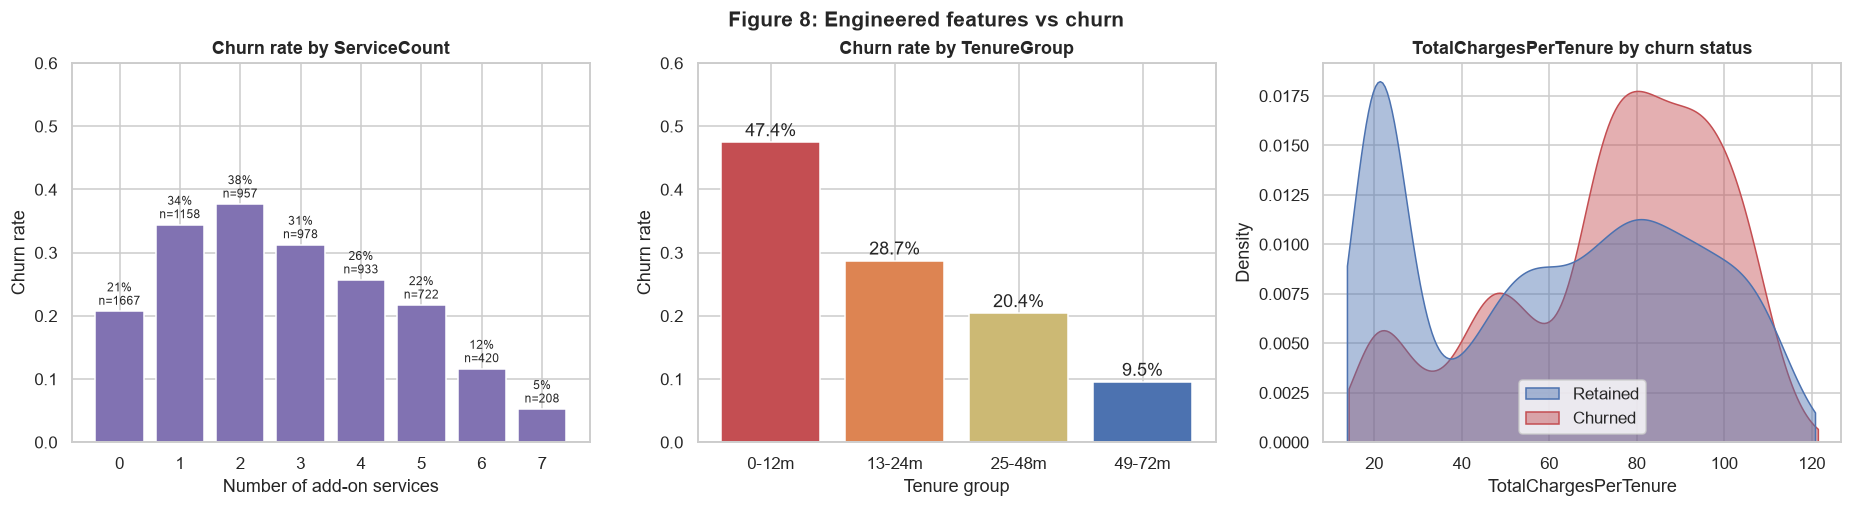

Churn by HasProtection, internet customers only:
HasProtection      No   Yes
InternetService            
DSL             0.427 0.140
Fiber optic     0.636 0.337 



,churn_rate_if_No,churn_rate_if_Yes
HasProtection,0.298,0.244
HasStreaming,0.228,0.303
IsAutoPay,0.347,0.160


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

sc = df.groupby("ServiceCount")["Churn"].agg(["mean", "size"])
axes[0].bar(sc.index, sc["mean"], color="#8172B2")
for x, (r, c) in sc.iterrows():
    axes[0].text(x, r + 0.01, f"{r:.0%}\nn={int(c)}", ha="center", fontsize=8)
axes[0].set(title="Churn rate by ServiceCount", xlabel="Number of add-on services", ylabel="Churn rate", ylim=(0, 0.6))

tg = df.groupby("TenureGroup")["Churn"].mean().reindex(dp.TENURE_LABELS)
axes[1].bar(tg.index, tg.values, color=[CHURN_COLOR, "#DD8452", "#CCB974", STAY_COLOR])
for i, r in enumerate(tg.values):
    axes[1].text(i, r + 0.01, f"{r:.1%}", ha="center")
axes[1].set(title="Churn rate by TenureGroup", xlabel="Tenure group", ylabel="Churn rate", ylim=(0, 0.6))

sns.kdeplot(x=df["TotalChargesPerTenure"], hue=df["Churn"].map(STATUS), fill=True, common_norm=False, alpha=0.45,
            palette=STATUS_PALETTE, ax=axes[2], cut=0)
axes[2].get_legend().set_title("")
axes[2].set_title("TotalChargesPerTenure by churn status")

fig.tight_layout()
finish_fig(fig, "engineered_features", "Engineered features vs churn")

# HasProtection is only meaningful for internet customers (others cannot buy protection services)
print("Churn by HasProtection, internet customers only:")
print(df[df["InternetService"] != "No"].groupby(["InternetService", "HasProtection"])["Churn"].mean().unstack().round(3), "\n")

flag_rates = pd.DataFrame({f: df.groupby(f)["Churn"].mean() for f in ["HasProtection", "HasStreaming", "IsAutoPay"]}).T
flag_rates.columns = [f"churn_rate_if_{c}" for c in flag_rates.columns]
flag_rates

**Figure 8. Engineered feature insights**
- **TenureGroup:** churn falls steadily from **47.4%** in the first year to **9.5%** after four years. The **first 12 months are the danger zone**.
- **ServiceCount:** the relationship is **not linear**. Customers with **zero add-ons** are mostly phone-only or low-engagement users with modest churn. Churn **peaks at 1-2 add-ons (34-38%)** and then falls steadily, to 12% with 6 services and 5% with all 7. Deep service adoption = lock-in. Tree models will capture this shape automatically.
- **TotalChargesPerTenure** separates the classes in the same way as MonthlyCharges: churners pay more per month on average.
- **IsAutoPay:** manual payers churn at **34.7% vs 16.0%** for auto-payers (2.2x).
- **HasProtection:** across all customers the gap looks small (29.8% vs 24.4%), because the "No" group includes low-churn customers with no internet service. **Among internet customers the effect is large.** Protection cuts churn from **63.6% to 33.7% for fiber** and from **42.7% to 14.0% for DSL**. This is a strong candidate retention lever.
- **HasStreaming:** streamers churn slightly *more* (30.3% vs 22.8%). This is consistent with streaming being bundled with expensive fiber plans.

## 6. Encoding & Scaling

Models need numeric inputs on comparable scales:
- **One-Hot Encoding** for all categorical features (e.g. `Contract` → `Contract_Month-to-month`, `Contract_One year`, `Contract_Two year`). We use `handle_unknown="ignore"` so unseen categories at prediction time cannot crash the pipeline.
- **StandardScaler** for numerical features (zero mean, unit variance). This is essential for Logistic Regression's regularisation and harmless for tree models.

> **Avoiding data leakage:** the encoder and scaler are wrapped in a `ColumnTransformer` that sits **inside an sklearn `Pipeline`**. During cross-validation they are re-fitted on each training fold only, so validation folds and the test set never influence the scaling statistics. The cell below fits the preprocessor once purely to show the output.

In [16]:
X, y, numeric_features, categorical_features = dp.split_features(df)
preprocessor = dp.build_preprocessor(numeric_features, categorical_features)

X_demo = pd.DataFrame(preprocessor.fit_transform(X), columns=preprocessor.get_feature_names_out())
print(f"Numeric features ({len(numeric_features)}): {numeric_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")
print(f"\nShape before encoding: {X.shape} -> after encoding: {X_demo.shape}")
X_demo[numeric_features].describe().loc[["mean", "std"]].round(3)

Numeric features (5): ['tenure', 'MonthlyCharges', 'TotalCharges', 'TotalChargesPerTenure', 'ServiceCount']
Categorical features (20): ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup', 'HasProtection', 'HasStreaming', 'IsAutoPay']

Shape before encoding: (7043, 25) -> after encoding: (7043, 58)


,tenure,MonthlyCharges,TotalCharges,TotalChargesPerTenure,ServiceCount
mean,-0.000,-0.000,-0.000,0.000,0.000
std,1.000,1.000,1.000,1.000,1.000


In [17]:
X_demo.filter(like="Contract").head()

,Contract_Month-to-month,Contract_One year,Contract_Two year
0,1.000,0.000,0.000
1,0.000,1.000,0.000
2,1.000,0.000,0.000
3,0.000,1.000,0.000
4,1.000,0.000,0.000


## Phase 1 Summary: Key Insights

1. **The classes are imbalanced (26.5% churn)**, so we will optimise ROC-AUC, inspect precision and recall, and use stratified splits.
2. **Contract type is the strongest signal.** Month-to-month customers churn at 42.7% vs 2.8% for two-year contracts.
3. **Fiber optic customers churn 2.2x more than DSL customers (H1 supported).** This may point to a pricing or quality issue with the premium product.
4. **Having a partner is associated with lower churn (H2 supported)**, but the effect is weaker.
5. **The first year is the danger zone.** Churn falls from 47% (0-12 months) to under 10% (4+ years).
6. **High monthly charges combined with short tenure** is the highest-risk region of the customer base.
7. **Protection and support services** (which halve churn among fiber customers) **and automatic payment** are associated with much lower churn. These are potential *levers* for retention offers.
8. `gender` and `PhoneService` show no relationship with churn.

**Next (Phase 2):** stratified train/test split, then Logistic Regression and Random Forest baselines evaluated with stratified K-Fold cross-validation.

## 7. Model Training & Cross-Validation

**Approach**
1. **Hold out a test set (20%)** with a stratified split. It is not touched during model selection or tuning and is used only once, for the final comparison in Section 8.
2. On the remaining 80%, evaluate each model with **stratified 5-fold cross-validation**. The model is trained on 4 folds and scored on the 5th, five times over. This gives a mean *and* a spread (± std), which tells us how stable the model is.
3. Every model is a single `Pipeline(preprocess → model)`, so the encoder and scaler are re-fitted on each training fold. **No information leaks from the validation fold.**

**Metrics:** **ROC-AUC** is the primary metric. We also report **PR-AUC** (average precision, which is more sensitive to how well the minority class is ranked), **Precision**, **Recall** and **F1** at the default 0.5 threshold, plus Accuracy for reference only.

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from src import modeling as ml

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape[0]:,} rows | churn rate {y_train.mean():.1%}")
print(f"Test : {X_test.shape[0]:,} rows | churn rate {y_test.mean():.1%}  <- locked away until Section 8")

Train: 5,634 rows | churn rate 26.5%
Test : 1,409 rows | churn rate 26.5%  <- locked away until Section 8


### 7.1 Baseline models and class-imbalance strategy

We train two model families, each **with and without class weighting**:
- **`class_weight=None`**: every customer counts equally. With 2.8 retained customers per churner, the model leans toward predicting "stay".
- **`class_weight="balanced"`**: errors on churners are weighted about 2.8x more heavily, pushing the model to catch more of them. This is our chosen imbalance strategy. It needs no synthetic data (unlike SMOTE) and works natively with both models.

A **Dummy classifier** that guesses at random in proportion to the class frequencies gives the "no-skill" reference point (ROC-AUC ≈ 0.5).

Model settings at this stage are sensible defaults. Hyperparameter tuning with GridSearchCV comes in Section 8.

In [19]:
cv = ml.make_cv()
baseline_models = {
    "Dummy (stratified guess)": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
    "LogReg": LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
    "LogReg (balanced)": LogisticRegression(max_iter=5000, class_weight="balanced", random_state=RANDOM_STATE),
    "RandomForest": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE),
    "RandomForest (balanced)": RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1,
                                                      random_state=RANDOM_STATE),
}

cv_raw, cv_rows = {}, []
for name, model in baseline_models.items():
    pipe = ml.make_pipeline(model, numeric_features, categorical_features)
    cv_raw[name] = ml.cross_validate_model(pipe, X_train, y_train, cv=cv)
    cv_rows.append(ml.summarize_cv(cv_raw[name], name))

print(f"Stratified {ml.N_FOLDS}-fold cross-validation on the training set (validation-fold mean ± std):")
ml.format_cv_table(cv_rows)

Stratified 5-fold cross-validation on the training set (validation-fold mean ± std):


,roc_auc,pr_auc,precision,recall,f1,accuracy,train_roc_auc,overfit_gap
model,,,,,,,,
Dummy (stratified guess),0.507 ± 0.017,0.269 ± 0.007,0.275 ± 0.025,0.278 ± 0.025,0.276 ± 0.025,0.614 ± 0.013,0.495,-0.011
LogReg,0.846 ± 0.012,0.661 ± 0.013,0.665 ± 0.019,0.527 ± 0.029,0.588 ± 0.022,0.804 ± 0.008,0.852,+0.006
LogReg (balanced),0.846 ± 0.012,0.659 ± 0.013,0.517 ± 0.014,0.791 ± 0.035,0.625 ± 0.020,0.748 ± 0.011,0.852,+0.006
RandomForest,0.825 ± 0.011,0.620 ± 0.031,0.631 ± 0.035,0.478 ± 0.022,0.543 ± 0.026,0.787 ± 0.013,1.000,+0.175
RandomForest (balanced),0.827 ± 0.012,0.613 ± 0.033,0.579 ± 0.018,0.652 ± 0.027,0.613 ± 0.020,0.782 ± 0.010,1.000,+0.173


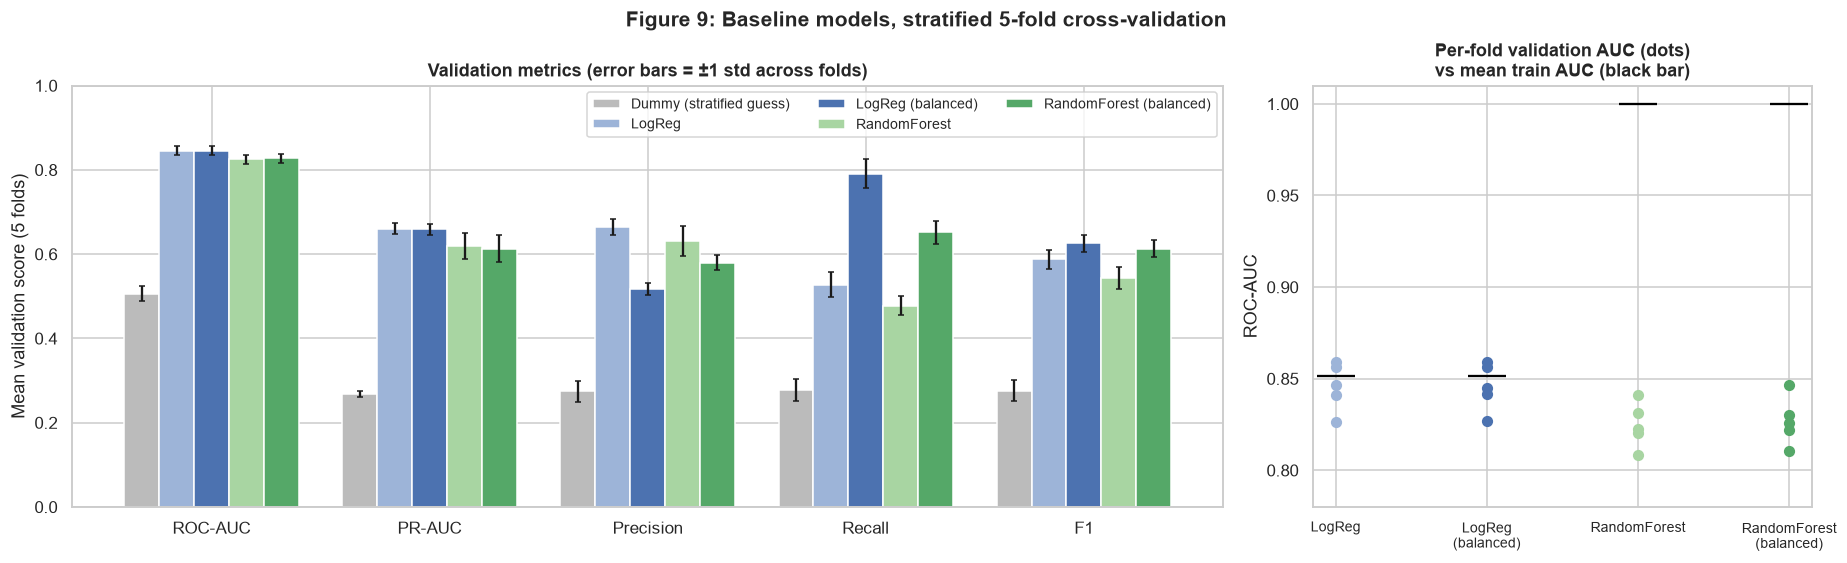

In [20]:
cv_summary = pd.DataFrame(cv_rows).set_index("model")
metrics_to_plot = ["roc_auc", "pr_auc", "precision", "recall", "f1"]
model_colors = {"Dummy (stratified guess)": "#BBBBBB", "LogReg": "#9DB4D8", "LogReg (balanced)": "#4C72B0",
                "RandomForest": "#A8D5A2", "RandomForest (balanced)": "#55A868"}

fig, axes = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [3, 1.3]})
width = 0.16
for i, (name, row) in enumerate(cv_summary.iterrows()):
    xs = np.arange(len(metrics_to_plot)) + (i - 2) * width
    axes[0].bar(xs, [row[f"{m}_mean"] for m in metrics_to_plot], width,
                yerr=[row[f"{m}_std"] for m in metrics_to_plot], capsize=2,
                label=name, color=model_colors[name])
axes[0].set_xticks(np.arange(len(metrics_to_plot)), ["ROC-AUC", "PR-AUC", "Precision", "Recall", "F1"])
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Mean validation score (5 folds)")
axes[0].legend(ncols=3, fontsize=9, loc="upper right")
axes[0].set_title("Validation metrics (error bars = ±1 std across folds)")

fold_auc = pd.DataFrame({n: r["test_roc_auc"] for n, r in cv_raw.items() if not n.startswith("Dummy")})
train_auc = pd.Series({n: r["train_roc_auc"].mean() for n, r in cv_raw.items() if not n.startswith("Dummy")})
for j, name in enumerate(fold_auc.columns):
    axes[1].scatter([j] * len(fold_auc), fold_auc[name], color=model_colors[name], s=40, zorder=3)
    axes[1].scatter(j, train_auc[name], marker="_", s=600, color="black", zorder=4)
axes[1].set_xticks(range(len(fold_auc.columns)), [n.replace(" (", "\n(") for n in fold_auc.columns], fontsize=9)
axes[1].set_ylabel("ROC-AUC")
axes[1].set_ylim(0.78, 1.01)
axes[1].set_title("Per-fold validation AUC (dots)\nvs mean train AUC (black bar)")

fig.tight_layout()
finish_fig(fig, "baseline_cv_comparison", "Baseline models, stratified 5-fold cross-validation")

**Figure 9 & cross-validation results**

| | ROC-AUC | Precision | Recall | Train AUC → overfit gap |
|---|---|---|---|---|
| Dummy (no skill) | 0.507 | 0.275 | 0.278 | - |
| LogReg | **0.846** ± 0.012 | 0.665 | 0.527 | 0.852 → +0.006 |
| LogReg (balanced) | **0.846** ± 0.012 | 0.517 | **0.791** | 0.852 → +0.006 |
| RandomForest | 0.825 ± 0.011 | 0.631 | 0.478 | **1.000 → +0.175** |
| RandomForest (balanced) | 0.827 ± 0.012 | 0.579 | 0.652 | **1.000 → +0.173** |

1. **Both model families are far better than chance** (AUC 0.83-0.85 vs 0.51 for the dummy). There is real, learnable signal.
2. **Logistic Regression is the stronger baseline** (AUC 0.846 vs 0.827). Phase 1 showed that most churn drivers (contract, tenure, fiber, payment method) have strong, roughly **monotonic** effects, which suits a linear model well.
3. **The default Random Forest overfits heavily.** Its fully grown trees memorise the training folds (train AUC 1.000) and lose about 0.17 AUC on unseen data. Limiting tree depth and leaf size in Phase 3's GridSearch should close much of this gap.
4. **Results are stable.** Fold-to-fold standard deviation is only about ±0.012 AUC, so the ranking of models is not a fluke of one particular split.
5. **Class weighting does not change ROC-AUC, but it changes the decisions.** AUC measures *ranking* quality, which weighting barely affects. Weighting shifts the 0.5 threshold toward the churn class. For Logistic Regression, **recall jumps from 53% to 79%** (we catch 3 in 4 churners instead of 1 in 2) while precision falls from 67% to 52%. Accuracy *drops* from 0.804 to 0.748 even though the model became more useful for retention, which is a concrete example of why accuracy is the wrong metric. Because the retention budget is better spent on a false alarm than lost on a missed churner, **we adopt `class_weight="balanced"` for all models from here on.** The exact operating point is tuned later by choosing the decision threshold.

### 7.2 Logistic Regression: odds ratios

Logistic Regression models the **log-odds** of churn as a linear sum of the features, so each coefficient has a direct reading. The **odds ratio = e^coef** is the multiplicative change in the odds of churn:
- For a **one-hot category** (e.g. `Contract_Month-to-month`), it is the change in odds relative to the average of the other levels of that feature. The model uses L2 regularisation with all levels kept, so the levels share the effect between them.
- For a **scaled numeric feature**, it is the change in odds for a **one standard-deviation increase**.

We fit the balanced Logistic Regression on the full training set to inspect its coefficients.

Identical 'No internet service' coefficients: [-0.251] (InternetService_No: -0.251)


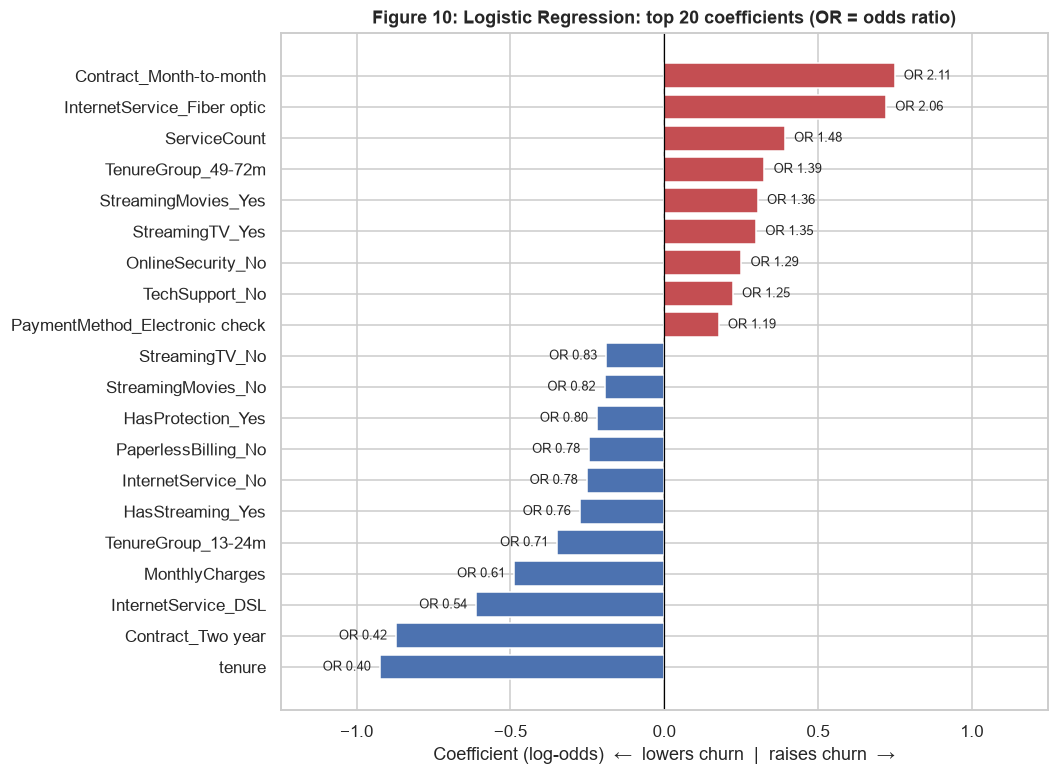

,coef,odds_ratio
feature,,
tenure,-0.924,0.397
Contract_Two year,-0.871,0.418
Contract_Month-to-month,0.749,2.115
InternetService_Fiber optic,0.721,2.057
InternetService_DSL,-0.610,0.543
MonthlyCharges,-0.487,0.614
ServiceCount,0.393,1.481
TenureGroup_13-24m,-0.347,0.707
TenureGroup_49-72m,0.326,1.385


In [21]:
logreg_pipe = ml.make_pipeline(baseline_models["LogReg (balanced)"], numeric_features, categorical_features)
logreg_pipe.fit(X_train, y_train)

coefs = pd.DataFrame({
    "feature": logreg_pipe.named_steps["preprocess"].get_feature_names_out(),
    "coef": logreg_pipe.named_steps["model"].coef_[0],
})
coefs["odds_ratio"] = np.exp(coefs["coef"])
coefs = coefs.reindex(coefs["coef"].abs().sort_values(ascending=False).index)

# The six "<service>_No internet service" dummies are identical copies of InternetService_No, so L2
# regularisation spreads one effect evenly across all seven columns. Plot InternetService_No as their stand-in.
no_internet_dupes = coefs["feature"].str.endswith("_No internet service")
print(f"Identical 'No internet service' coefficients: {coefs.loc[no_internet_dupes, 'coef'].round(3).unique()}"
      f" (InternetService_No: {coefs.loc[coefs.feature == 'InternetService_No', 'coef'].round(3).item()})")
top = coefs[~no_internet_dupes].head(20).sort_values("coef")
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(top["feature"], top["coef"], color=[CHURN_COLOR if c > 0 else STAY_COLOR for c in top["coef"]])
for yi, (c, o) in enumerate(zip(top["coef"], top["odds_ratio"])):
    ax.text(c + (0.03 if c > 0 else -0.03), yi, f"OR {o:.2f}", va="center", ha="left" if c > 0 else "right", fontsize=8.5)
ax.axvline(0, color="black", lw=0.8)
lim = top["coef"].abs().max() * 1.35
ax.set_xlim(-lim, lim)
ax.set_xlabel("Coefficient (log-odds)  ←  lowers churn  |  raises churn  →")
finish_fig(fig, "logreg_odds_ratios", "Logistic Regression: top 20 coefficients (OR = odds ratio)", ax)

coefs[~no_internet_dupes].head(12).set_index("feature")

In [22]:
# Multicollinearity check: tenure, TotalCharges, MonthlyCharges and TotalChargesPerTenure are tightly linked,
# which makes their individual linear coefficients unstable and hard to read on their own.
X_train[numeric_features].corr().round(2)

,tenure,MonthlyCharges,TotalCharges,TotalChargesPerTenure,ServiceCount
tenure,1.000,0.260,0.830,0.260,0.530
MonthlyCharges,0.260,1.000,0.650,1.000,0.770
TotalCharges,0.830,0.650,1.000,0.650,0.790
TotalChargesPerTenure,0.260,1.000,0.650,1.000,0.770
ServiceCount,0.530,0.770,0.790,0.770,1.000


**Figure 10. Reading the odds ratios**

The **most robust signals** agree with Phase 1 and do not depend on correlated features:
- **Contract.** Month-to-month **roughly doubles the odds of churn (OR 2.11)**, while a two-year contract cuts them by about 58% (OR 0.42).
- **Fiber optic internet roughly doubles the odds (OR 2.06)**, even *after* controlling for price and contract. This again points to a product-experience issue, not just price.
- **Tenure.** Each extra standard deviation of tenure (about 25 months) cuts the odds of churn by **about 60% (OR 0.40)**.
- **No Online Security** raises the odds (OR 1.29).

**Caveat on correlated features.** `MonthlyCharges` shows OR 0.61 (*lower* churn as the bill rises), which seems to contradict Figure 2. The reason is **multicollinearity**. In this dataset the monthly bill is almost entirely determined by the services a customer has, and `TotalChargesPerTenure` is effectively a copy of `MonthlyCharges` (r = 1.00 in the table above). Once fiber, the streaming add-ons and `ServiceCount` are in the model, the charge coefficient only captures what is *left over*. The same effect explains the opposite signs on `StreamingTV_Yes` (+) and `HasStreaming_Yes` (−), and on `tenure` (−) and `TenureGroup_49-72m` (+). **Coefficients for correlated features must be read together, not one at a time.** This weakness of linear models is one reason the brief asks for SHAP.

> **Note on `TotalChargesPerTenure`:** in this dataset `TotalCharges ≈ tenure × MonthlyCharges`, so the ratio almost exactly reproduces `MonthlyCharges` (we checked: the small difference between the two carries no churn signal). We keep it because the brief requires it. It does not hurt predictive performance, but it adds no new information either.

### 7.3 Random Forest: impurity-based feature importance

Random Forest offers a quick global view: how much each feature reduces impurity across all trees. This measure is **biased toward continuous, high-cardinality features** (such as tenure and charges), which have many possible split points. We use it here only as a first look. **SHAP (Section 9) is the rigorous interpretation.**

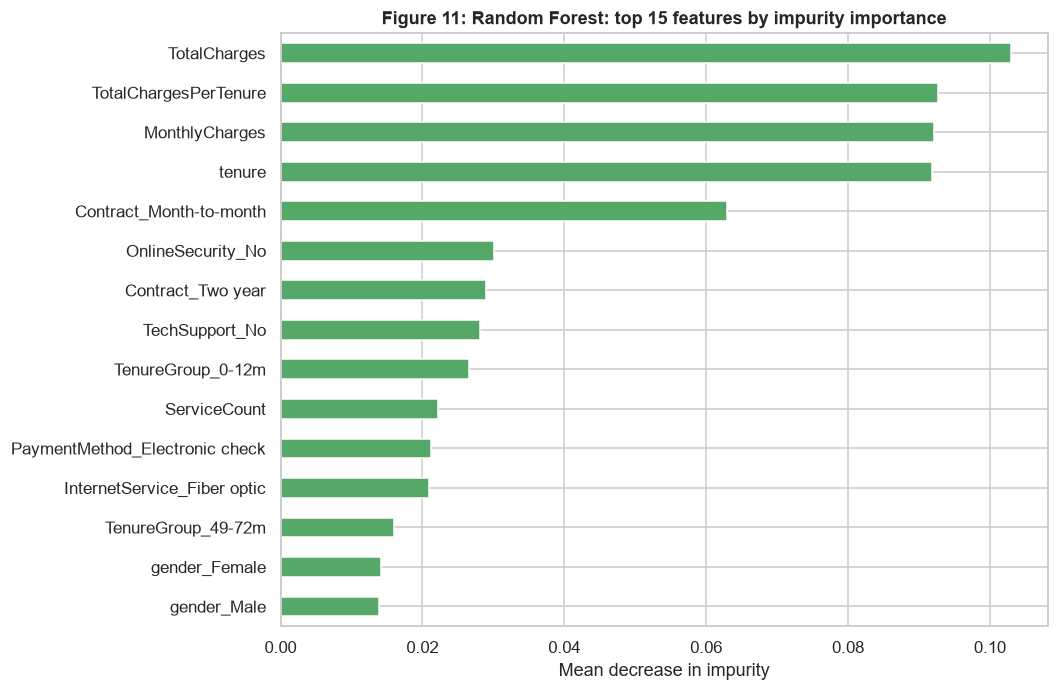

In [23]:
rf_pipe = ml.make_pipeline(baseline_models["RandomForest (balanced)"], numeric_features, categorical_features)
rf_pipe.fit(X_train, y_train)

rf_importance = pd.Series(rf_pipe.named_steps["model"].feature_importances_,
                          index=rf_pipe.named_steps["preprocess"].get_feature_names_out()).sort_values()
fig, ax = plt.subplots(figsize=(9, 7))
rf_importance.tail(15).plot.barh(ax=ax, color="#55A868")
ax.set_xlabel("Mean decrease in impurity")
finish_fig(fig, "rf_feature_importance", "Random Forest: top 15 features by impurity importance", ax)

**Figure 11.** The forest leans on the continuous features (TotalCharges, the charge features, tenure) and on `Contract_Month-to-month`, `OnlineSecurity_No` and `TechSupport_No`. Two warning signs show why **we will not use impurity importance for business conclusions**:
- **`gender_Female` / `gender_Male` appear in the top 15**, even though Phase 1 found gender has **no relationship** with churn (p = 0.49). Fully grown trees split on gender to memorise noise in the training data. This matches the +0.17 overfitting gap.
- The importance of tenure is **split across** `tenure`, `TotalCharges` and `TenureGroup`, and the importance of price across `MonthlyCharges`, `TotalChargesPerTenure` and `TotalCharges`, so each looks less important than the underlying driver really is.

SHAP values on the tuned model (Section 9) address both problems.

## Phase 2 Summary

1. **Leak-free evaluation is in place:** a stratified 80/20 split (test set locked away), stratified 5-fold CV, and preprocessing inside the pipeline.
2. **Best baseline: Logistic Regression, ROC-AUC 0.846 ± 0.012.** Random Forest reaches 0.827 but **overfits badly** (train AUC 1.000).
3. **Imbalance strategy: `class_weight="balanced"`.** It keeps ROC-AUC unchanged and moves the operating point toward catching churners (LogReg recall 53% → 79%). We keep it for all models from here on.
4. **Interpretation so far:** month-to-month contracts, fiber internet and short tenure are the strongest and most consistent churn drivers. Correlated charge and service features cannot be read one at a time, which motivates SHAP.

**Next (Phase 3):** XGBoost and LightGBM, GridSearchCV tuning for all models (including regularising the Random Forest), a single final comparison on the untouched test set (ROC curves, confusion matrices, precision-recall), and choosing the business decision threshold.

## 8. Boosting & Hyperparameter Tuning

### 8.1 Gradient boosting models

**Gradient boosting** builds shallow trees *sequentially*, with each new tree correcting the errors of the ones before it. It is usually the strongest model family for tabular data. We train both popular implementations:
- **XGBoost**, which handles imbalance with `scale_pos_weight = #retained / #churned` (about 2.77), the boosting equivalent of `class_weight="balanced"`.
- **LightGBM**, with `class_weight="balanced"`.

First, a default-settings run of each, so we can measure how much tuning adds.

In [24]:
import time
import joblib
from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.metrics import roc_curve, precision_recall_curve
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from src import evaluation as ev

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {scale_pos_weight:.2f}")

default_boosters = {
    "XGBoost (default)": XGBClassifier(scale_pos_weight=scale_pos_weight, tree_method="hist", n_jobs=-1,
                                       random_state=RANDOM_STATE),
    "LightGBM (default)": LGBMClassifier(class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE, verbose=-1),
}
for name, model in default_boosters.items():
    pipe = ml.make_pipeline(model, numeric_features, categorical_features)
    cv_raw[name] = ml.cross_validate_model(pipe, X_train, y_train, cv=cv)
    cv_rows.append(ml.summarize_cv(cv_raw[name], name))

ml.format_cv_table(cv_rows).loc[["LogReg (balanced)", "RandomForest (balanced)", *default_boosters]]

scale_pos_weight = 2.77


,roc_auc,pr_auc,precision,recall,f1,accuracy,train_roc_auc,overfit_gap
model,,,,,,,,
LogReg (balanced),0.846 ± 0.012,0.659 ± 0.013,0.517 ± 0.014,0.791 ± 0.035,0.625 ± 0.020,0.748 ± 0.011,0.852,+0.006
RandomForest (balanced),0.827 ± 0.012,0.613 ± 0.033,0.579 ± 0.018,0.652 ± 0.027,0.613 ± 0.020,0.782 ± 0.010,1.000,+0.173
XGBoost (default),0.824 ± 0.008,0.622 ± 0.018,0.558 ± 0.025,0.646 ± 0.015,0.599 ± 0.019,0.770 ± 0.014,0.996,+0.172
LightGBM (default),0.838 ± 0.008,0.647 ± 0.023,0.552 ± 0.012,0.724 ± 0.015,0.626 ± 0.011,0.771 ± 0.008,0.965,+0.127


**With default settings, the boosters do *not* beat Logistic Regression.** Default XGBoost (AUC 0.824) and LightGBM (0.838) both overfit (train AUC 0.996 / 0.965). Their default trees are deep and numerous enough to memorise a 5,600-customer dataset. Gradient boosting is not automatically better: it needs to be tuned.

### 8.2 Hyperparameter tuning with GridSearchCV

Each model is tuned with an exhaustive **GridSearchCV** over the grid below. Every combination is scored with the **same stratified 5-fold CV** as before, the selection metric is **ROC-AUC**, and all models use balanced class weighting. Tuning happens on the training set only. The test set is still locked.

| Model | Hyperparameters searched | Why these |
|---|---|---|
| Logistic Regression | `C` (inverse regularisation strength), `l1_ratio` (0 = L2 / ridge, 1 = L1 / lasso, 0.5 = elastic net) | Regularisation controls coefficient size and can drop redundant features (useful given the collinearity in §7.2) |
| Random Forest | `max_depth`, `min_samples_leaf`, `max_features` | Directly targets the overfitting seen in §7.1 (train AUC = 1.0) |
| XGBoost | `learning_rate`, `max_depth`, `n_estimators`, `subsample`, `min_child_weight` | Learning rate × number of trees controls how fast the model fits; depth controls interaction complexity |
| LightGBM | `learning_rate`, `num_leaves`, `n_estimators`, `min_child_samples` | LightGBM grows trees leaf-wise, so `num_leaves` is its main complexity control |

In [25]:
search_spaces = {
    "Logistic Regression": (
        LogisticRegression(solver="saga", max_iter=5000, class_weight="balanced", random_state=RANDOM_STATE),
        {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3], "model__l1_ratio": [0, 0.5, 1]},
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=400, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
        {"model__max_depth": [6, 10, 15, None], "model__min_samples_leaf": [1, 5, 10, 20],
         "model__max_features": ["sqrt", 0.3]},
    ),
    "XGBoost": (
        XGBClassifier(scale_pos_weight=scale_pos_weight, colsample_bytree=0.8, tree_method="hist", n_jobs=-1,
                      random_state=RANDOM_STATE),
        {"model__learning_rate": [0.02, 0.05, 0.1], "model__max_depth": [2, 3, 4, 6],
         "model__n_estimators": [200, 400], "model__subsample": [0.8, 1.0], "model__min_child_weight": [1, 5]},
    ),
    "LightGBM": (
        LGBMClassifier(class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE, verbose=-1),
        {"model__learning_rate": [0.02, 0.05, 0.1], "model__num_leaves": [4, 8, 16, 31],
         "model__n_estimators": [200, 400], "model__min_child_samples": [20, 50]},
    ),
}

searches = {}
for name, (model, grid) in search_spaces.items():
    start = time.perf_counter()
    search = GridSearchCV(ml.make_pipeline(model, numeric_features, categorical_features), grid,
                          scoring=ml.SCORING, refit="roc_auc", cv=cv, return_train_score=True)
    search.fit(X_train, y_train)
    searches[name] = search
    n_combos = len(search.cv_results_["params"])
    best = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    print(f"{name:20s} {n_combos:3d} combos x {ml.N_FOLDS} folds in {time.perf_counter() - start:5.1f}s | "
          f"best CV AUC {search.best_score_:.4f} | {best}")

Logistic Regression   18 combos x 5 folds in  46.3s | best CV AUC 0.8462 | {'C': 0.03, 'l1_ratio': 0}


Random Forest         32 combos x 5 folds in 162.2s | best CV AUC 0.8481 | {'max_depth': 6, 'max_features': 0.3, 'min_samples_leaf': 20}


XGBoost               96 combos x 5 folds in 154.1s | best CV AUC 0.8498 | {'learning_rate': 0.02, 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 400, 'subsample': 0.8}


LightGBM              48 combos x 5 folds in  75.3s | best CV AUC 0.8486 | {'learning_rate': 0.02, 'min_child_samples': 50, 'n_estimators': 400, 'num_leaves': 4}


In [26]:
baseline_names = {"Logistic Regression": "LogReg (balanced)", "Random Forest": "RandomForest (balanced)",
                  "XGBoost": "XGBoost (default)", "LightGBM": "LightGBM (default)"}

baseline_auc = pd.DataFrame(cv_rows).set_index("model")["roc_auc_mean"]

tuned_rows = []
for name, search in searches.items():
    res, i = search.cv_results_, search.best_index_
    row = {"model": name, "baseline_cv_auc": baseline_auc[baseline_names[name]]}
    for metric in ml.SCORING:
        row[f"{metric}_mean"] = res[f"mean_test_{metric}"][i]
        row[f"{metric}_std"] = res[f"std_test_{metric}"][i]
    row["train_roc_auc"] = res["mean_train_roc_auc"][i]
    row["overfit_gap"] = row["train_roc_auc"] - row["roc_auc_mean"]
    tuned_rows.append(row)
tuned_summary = pd.DataFrame(tuned_rows).set_index("model")

display_cols = {"baseline_cv_auc": "baseline AUC", "roc_auc_mean": "tuned AUC", "roc_auc_std": "± std",
                "pr_auc_mean": "PR-AUC", "precision_mean": "precision", "recall_mean": "recall", "f1_mean": "F1",
                "train_roc_auc": "train AUC", "overfit_gap": "overfit gap"}
tuned_summary[list(display_cols)].rename(columns=display_cols).sort_values("tuned AUC", ascending=False).round(4)

,baseline AUC,tuned AUC,± std,PR-AUC,precision,recall,F1,train AUC,overfit gap
model,,,,,,,,,
XGBoost,0.824,0.850,0.012,0.667,0.518,0.813,0.632,0.863,0.013
LightGBM,0.838,0.849,0.011,0.666,0.519,0.808,0.632,0.864,0.016
Random Forest,0.827,0.848,0.011,0.664,0.522,0.799,0.631,0.875,0.027
Logistic Regression,0.846,0.846,0.012,0.661,0.524,0.787,0.629,0.850,0.004


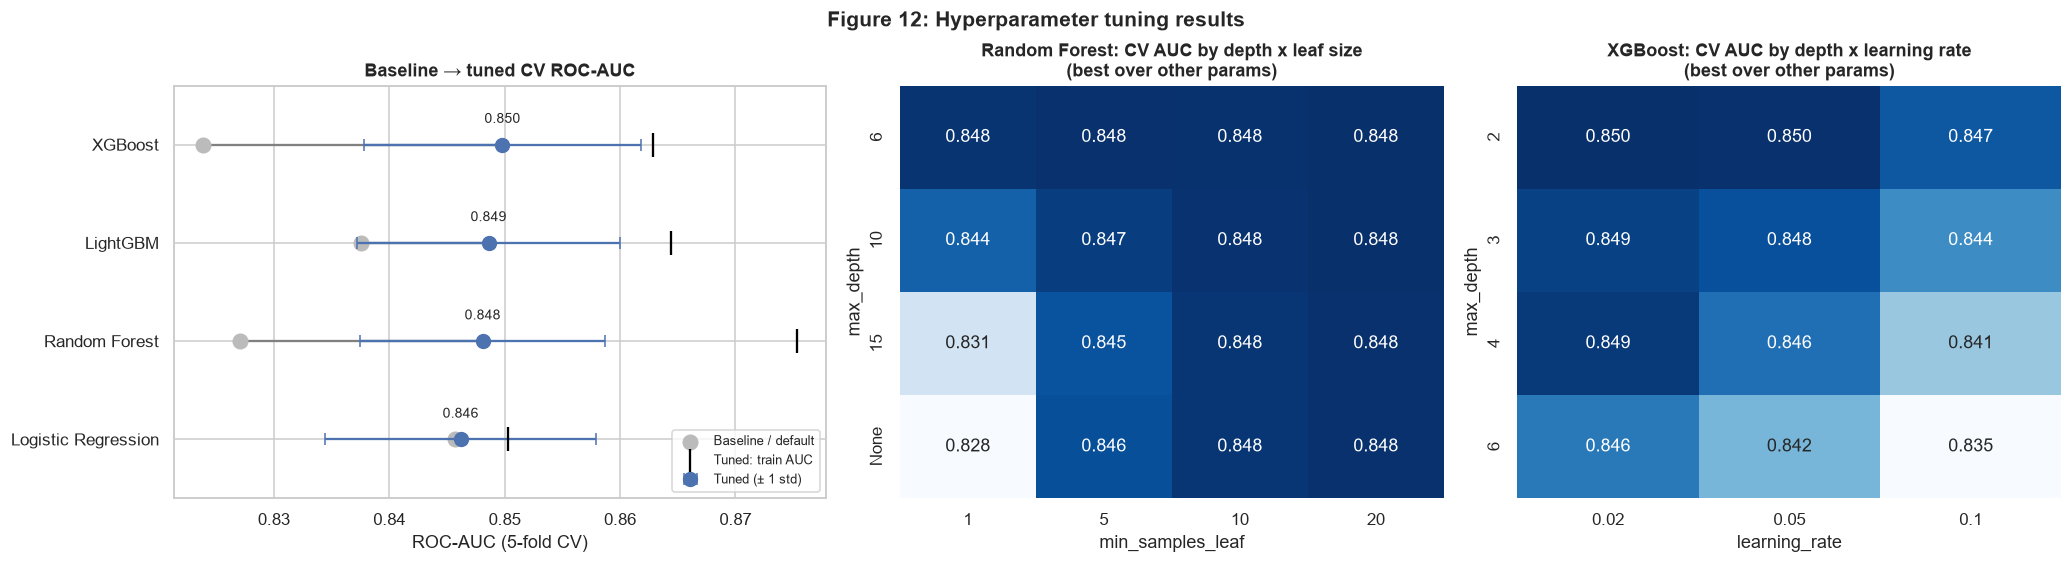

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5), gridspec_kw={"width_ratios": [1.2, 1, 1]})

ax = axes[0]
order = tuned_summary.sort_values("roc_auc_mean").index
for yi, name in enumerate(order):
    r = tuned_summary.loc[name]
    ax.plot([r["baseline_cv_auc"], r["roc_auc_mean"]], [yi, yi], color="grey", lw=1.5, zorder=1)
    ax.scatter(r["baseline_cv_auc"], yi, color="#BBBBBB", s=90, zorder=2, label="Baseline / default" if yi == 0 else None)
    ax.errorbar(r["roc_auc_mean"], yi, xerr=r["roc_auc_std"], fmt="o", color="#4C72B0", ms=9, capsize=4, zorder=3,
                label="Tuned (± 1 std)" if yi == 0 else None)
    ax.scatter(r["train_roc_auc"], yi, marker="|", s=250, color="black", zorder=3, label="Tuned: train AUC" if yi == 0 else None)
    ax.text(r["roc_auc_mean"], yi + 0.22, f"{r['roc_auc_mean']:.3f}", ha="center", fontsize=9)
ax.set_yticks(range(len(order)), order)
ax.set_xlabel("ROC-AUC (5-fold CV)")
ax.set_ylim(-0.6, len(order) - 0.4)
ax.legend(fontsize=8.5, loc="lower right")
ax.set_title("Baseline → tuned CV ROC-AUC")

def grid_heatmap(ax, search, row_param, col_param, title):
    res = pd.DataFrame(search.cv_results_)
    # Stringify params so None (e.g. unlimited max_depth) is kept as a row instead of dropped as NaN.
    rows = res[f"param_model__{row_param}"].map(lambda v: "None" if v is None or pd.isna(v) else str(v))
    pivot = res.assign(_row=rows).pivot_table(index="_row", columns=f"param_model__{col_param}",
                                              values="mean_test_roc_auc", aggfunc="max", sort=False)
    sns.heatmap(pivot, annot=True, fmt=".3f", cmap="Blues", ax=ax, cbar=False)
    ax.set(title=title, ylabel=row_param, xlabel=col_param)

grid_heatmap(axes[1], searches["Random Forest"], "max_depth", "min_samples_leaf",
             "Random Forest: CV AUC by depth x leaf size\n(best over other params)")
grid_heatmap(axes[2], searches["XGBoost"], "max_depth", "learning_rate",
             "XGBoost: CV AUC by depth x learning rate\n(best over other params)")
fig.tight_layout()
finish_fig(fig, "tuning_results", "Hyperparameter tuning results")

**Figure 12 & tuning results**

| Model | Baseline → tuned CV AUC | Train AUC (overfit gap) | Best hyperparameters |
|---|---|---|---|
| **XGBoost** | 0.824 → **0.850** | 0.863 (+0.013) | `max_depth=2`, `learning_rate=0.02`, `n_estimators=400`, `subsample=0.8`, `min_child_weight=5` |
| LightGBM | 0.838 → 0.849 | 0.864 (+0.016) | `num_leaves=4`, `learning_rate=0.02`, `n_estimators=400`, `min_child_samples=50` |
| Random Forest | 0.827 → 0.848 | 0.875 (+0.027) | `max_depth=6`, `min_samples_leaf=20`, `max_features=0.3` |
| Logistic Regression | 0.846 → 0.846 | 0.850 (+0.004) | `C=0.03`, `l1_ratio=0` (L2 / ridge) |

1. **Tuning works by fixing overfitting, not by adding complexity.** Every tree model's best setting is a *simpler* model. Random Forest's overfit gap fell from +0.173 to +0.027, and XGBoost's from +0.172 to +0.013.
2. **The heatmaps show the same pattern.** In the Random Forest grid, deep trees with tiny leaves are the worst cells (bottom-left). Shallow trees or large minimum leaf sizes do best. In the XGBoost grid, AUC falls steadily as trees get deeper and the learning rate rises. The best XGBoost uses **depth-2 trees**, so each tree can capture at most a two-feature interaction (e.g. *fiber × month-to-month*).
3. **All four models converge on a CV AUC of 0.846-0.850.** This looks like the *information ceiling* of this dataset: the remaining uncertainty comes from factors not recorded in the data (competitor offers, service outages, life events), not from model choice. Logistic Regression barely moved because it was already near the ceiling.

### 8.3 Final evaluation on the held-out test set

This is the **first and only time** the 1,409 test customers are used. Each tuned pipeline, already refitted by GridSearchCV on the full training set, predicts churn scores for the test customers. We report:
- **ROC-AUC with a 95% bootstrap confidence interval** (1,000 resamples of the test set). With 1,409 customers, small AUC differences can be noise.
- Threshold-dependent metrics at the default **0.5** cut-off (the business threshold is chosen in §8.5).

In [28]:
final_models = {name: s.best_estimator_ for name, s in searches.items()}
test_proba = {name: m.predict_proba(X_test)[:, 1] for name, m in final_models.items()}

test_rows = []
for name, proba in test_proba.items():
    m = ev.classification_metrics(y_test, proba)
    lo, hi = ev.bootstrap_auc_ci(y_test, proba)
    test_rows.append({"model": name, "test_roc_auc": m["roc_auc"], "auc_95ci": f"[{lo:.3f}, {hi:.3f}]",
                      "cv_roc_auc": tuned_summary.loc[name, "roc_auc_mean"],
                      **{k: m[k] for k in ("pr_auc", "precision", "recall", "f1", "accuracy")}})
test_results = pd.DataFrame(test_rows).set_index("model").sort_values("test_roc_auc", ascending=False)
test_results.round(4)

,test_roc_auc,auc_95ci,cv_roc_auc,pr_auc,precision,recall,f1,accuracy
model,,,,,,,,
LightGBM,0.847,"[0.825, 0.869]",0.849,0.664,0.512,0.805,0.626,0.745
XGBoost,0.846,"[0.824, 0.867]",0.850,0.663,0.513,0.807,0.627,0.745
Random Forest,0.845,"[0.823, 0.865]",0.848,0.657,0.522,0.802,0.632,0.752
Logistic Regression,0.841,"[0.819, 0.861]",0.846,0.630,0.514,0.778,0.619,0.746


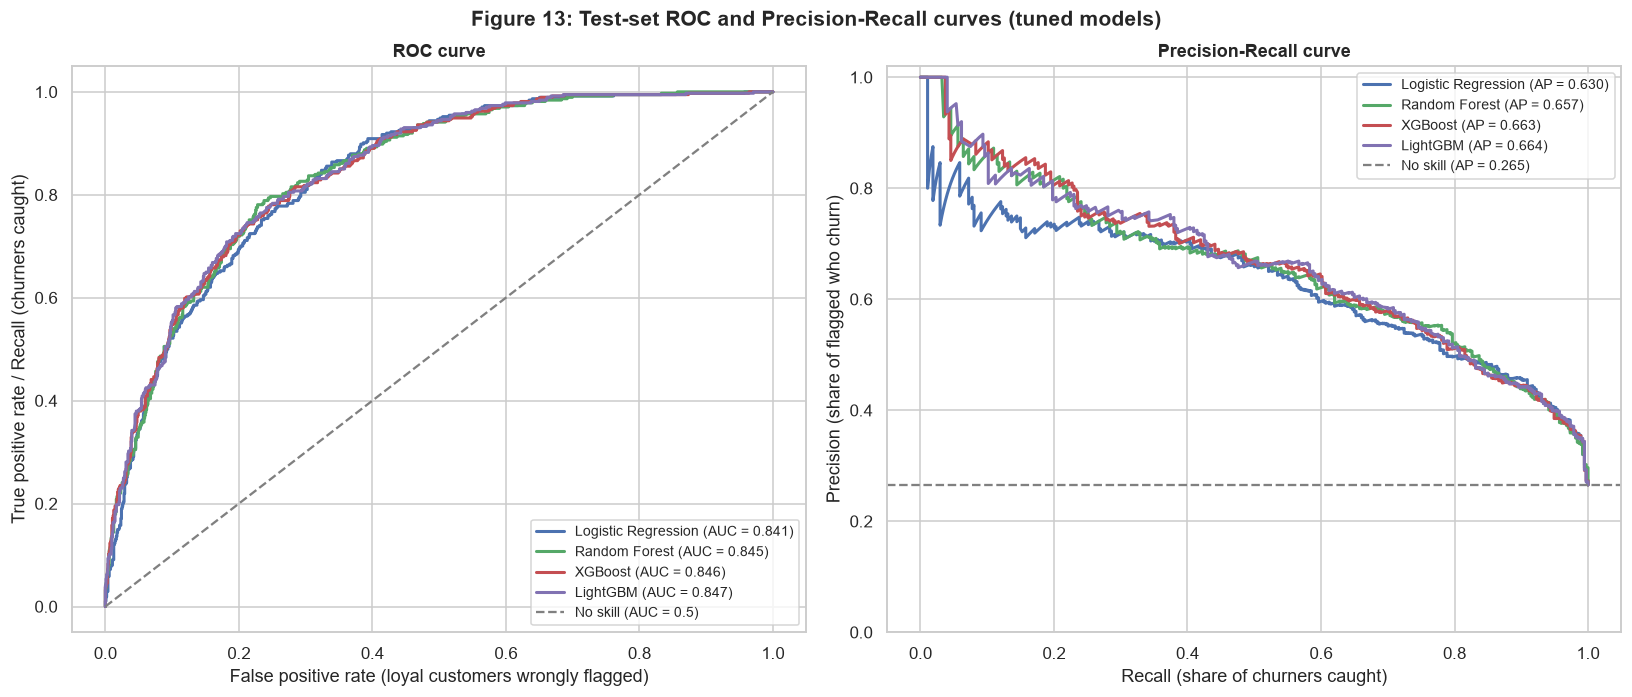

In [29]:
model_palette = {"Logistic Regression": "#4C72B0", "Random Forest": "#55A868", "XGBoost": "#C44E52", "LightGBM": "#8172B2"}

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
for name, proba in test_proba.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, lw=2, color=model_palette[name], label=f"{name} (AUC = {test_results.loc[name, 'test_roc_auc']:.3f})")
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec, prec, lw=2, color=model_palette[name], label=f"{name} (AP = {test_results.loc[name, 'pr_auc']:.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="grey", label="No skill (AUC = 0.5)")
axes[0].set(xlabel="False positive rate (loyal customers wrongly flagged)", ylabel="True positive rate / Recall (churners caught)",
            title="ROC curve")
axes[1].axhline(y_test.mean(), ls="--", color="grey", label=f"No skill (AP = {y_test.mean():.3f})")
axes[1].set(xlabel="Recall (share of churners caught)", ylabel="Precision (share of flagged who churn)",
            title="Precision-Recall curve", ylim=(0, 1.02))
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "upper right", fontsize=9)
fig.tight_layout()
finish_fig(fig, "test_roc_pr_curves", "Test-set ROC and Precision-Recall curves (tuned models)")

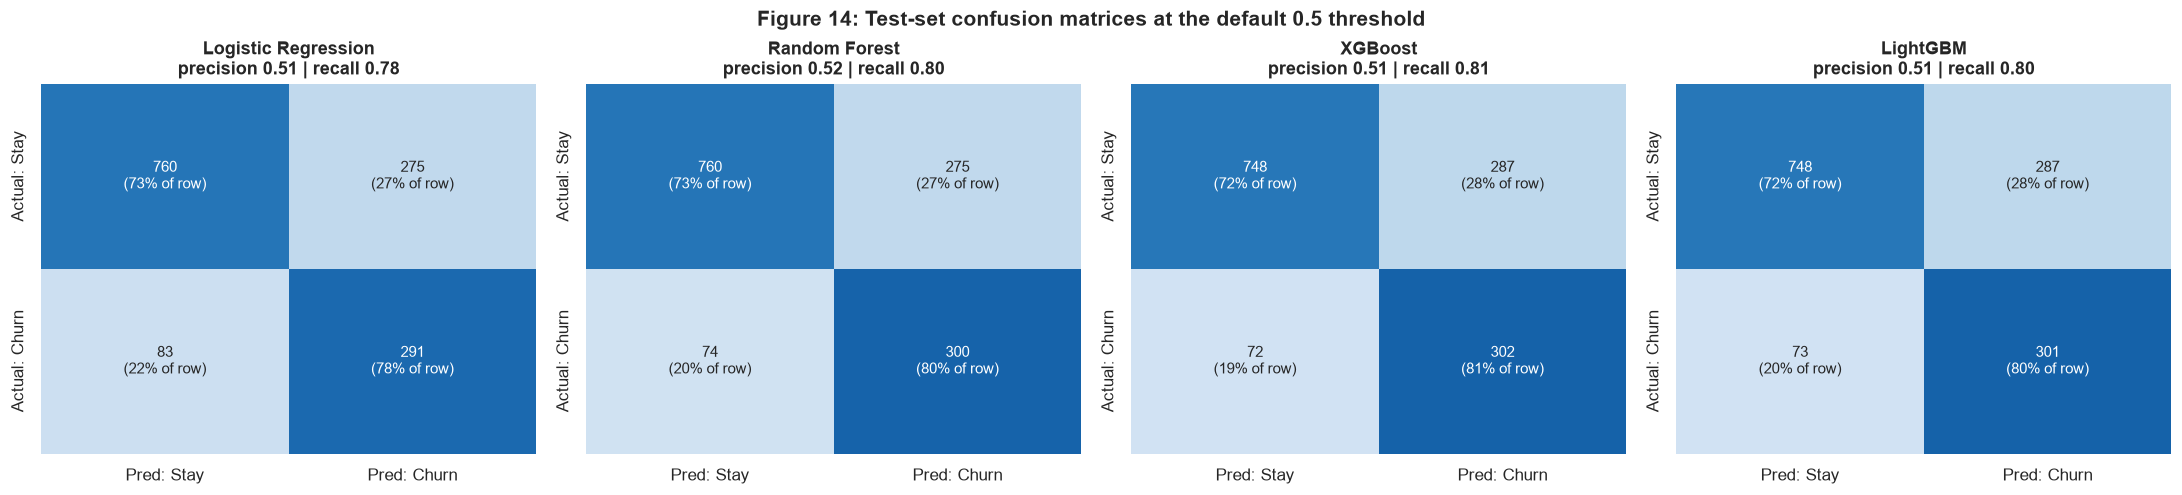

In [30]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.4))
for ax, (name, proba) in zip(axes, test_proba.items()):
    cm = ev.confusion_frame(y_test, (proba >= 0.5).astype(int))
    row_pct = cm.div(cm.sum(axis=1), axis=0)
    labels = np.array([[f"{n:,}\n({p:.0%} of row)" for n, p in zip(cr, pr)] for cr, pr in zip(cm.values, row_pct.values)])
    sns.heatmap(row_pct, annot=labels, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                annot_kws={"fontsize": 10})
    ax.set_title(f"{name}\nprecision {test_results.loc[name, 'precision']:.2f} | recall {test_results.loc[name, 'recall']:.2f}")
    ax.set_ylabel("")
fig.tight_layout()
finish_fig(fig, "test_confusion_matrices", "Test-set confusion matrices at the default 0.5 threshold")

In [31]:
# Are the test-set AUC differences real? Paired bootstrap: resample the same customers for both models.
best_test = test_results.index[0]
rows = []
for other in test_results.index[1:]:
    mean_diff, (lo, hi), p_le0 = ev.bootstrap_auc_diff(y_test, test_proba[best_test], test_proba[other])
    rows.append({"comparison": f"{best_test} - {other}", "AUC diff": mean_diff, "95% CI": f"[{lo:+.3f}, {hi:+.3f}]",
                 "P(diff <= 0)": p_le0})
pd.DataFrame(rows).set_index("comparison").round(4)

,AUC diff,95% CI,P(diff <= 0)
comparison,,,
LightGBM - XGBoost,0.002,"[-0.000, +0.004]",0.043
LightGBM - Random Forest,0.002,"[-0.002, +0.007]",0.183
LightGBM - Logistic Regression,0.007,"[+0.000, +0.013]",0.023


**Test-set results (Figures 13-14)**

| Model | Test AUC [95% CI] | CV AUC | PR-AUC | Recall @0.5 | Precision @0.5 |
|---|---|---|---|---|---|
| LightGBM | 0.847 [0.825, 0.869] | 0.849 | 0.664 | 0.805 | 0.512 |
| **XGBoost** | 0.846 [0.824, 0.867] | **0.850** | 0.663 | **0.807** | 0.513 |
| Random Forest | 0.845 [0.823, 0.865] | 0.848 | 0.657 | 0.802 | 0.522 |
| Logistic Regression | 0.841 [0.819, 0.861] | 0.846 | 0.630 | 0.778 | 0.514 |

1. **The models generalise.** Test AUCs are within 0.005 of their CV estimates, which confirms the cross-validation was honest and that the tuning did not overfit the validation folds.
2. **The tree models are statistically tied.** The confidence intervals overlap almost entirely, and the paired-bootstrap difference between the top two is +0.002 (CI ≈ [0.000, +0.004]), which is not meaningful in practice.
3. **The boosters beat Logistic Regression where it matters most for targeting:** at the *top of the risk list*. The PR curve shows that, while catching the first 10-20% of churners (roughly the 75 highest-risk customers), the tree models keep **80-90% precision**, while Logistic Regression drops to about 73-77%. The PR-AUC gap (0.663 vs 0.630) is larger than the ROC-AUC gap. If the retention budget only covers the riskiest few hundred customers, that difference counts.
4. At the default 0.5 threshold every model **catches about 80% of churners**, at the cost of roughly 1 in 2 flagged customers being a false alarm (Figure 14). §8.5 shows that 0.5 is not the best business operating point.

### 8.4 Model selection

We choose **XGBoost** as the final model:
- It has the **highest cross-validated AUC (0.850)**. Selection is based on CV, *not* on the test set. Picking whichever model happened to score best on the test set would turn the test set into another tuning set and inflate the reported performance. LightGBM's 0.001 test-set edge is well within noise.
- It has the **smallest overfit gap among the tree models** (+0.013), with the simplest structure (depth-2 trees).
- It has **strong top-of-list precision** (PR-AUC 0.663), which suits a budget-limited retention campaign.
- It is a tree model, so it captures non-linear effects (the ServiceCount hump, the first-year danger zone) and interactions without hand-crafted terms, and **SHAP's exact `TreeExplainer`** can explain it in Phase 4.

In [32]:
FINAL_MODEL_NAME = "XGBoost"
final_pipeline = final_models[FINAL_MODEL_NAME]
print(f"Selected model: {FINAL_MODEL_NAME}")
print({k.replace("model__", ""): v for k, v in searches[FINAL_MODEL_NAME].best_params_.items()})

Selected model: XGBoost
{'learning_rate': 0.02, 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 400, 'subsample': 0.8}


### 8.5 Choosing the decision threshold: a business decision

A 0.5 cut-off is arbitrary. The right threshold depends on the **cost of a retention offer** and the **value of saving a churner**:
- **Lower threshold:** contact more customers, catch more churners (higher recall), but spend more on offers to customers who would have stayed (lower precision).
- **Higher threshold:** a cheaper, more precise campaign, but more churners slip through.

**Campaign value model (illustrative assumptions, easy to replace with ConnectTel's real figures):**

| Assumption | Value |
|---|---|
| Cost of one retention offer | **\$100** per contacted customer |
| Offer success rate | **30%** of contacted *real* churners are retained |
| Value of a retained customer | **12 months × their monthly charge** |

Net value = Σ (30% × 12 × monthly charge of each churner caught) − \$100 × customers contacted.

To avoid tuning on the test set, the threshold is chosen using **out-of-fold predictions on the training set** (`cross_val_predict`): every training customer is scored by a model that never saw them. The chosen threshold is then applied unchanged to the test set.

> Because of class weighting, the model's scores are **not calibrated probabilities**. A score of 0.5 does not mean "50% chance of churn". The threshold is therefore a cut-off on the *risk score*, chosen for its business outcome.

In [33]:
oof_proba = cross_val_predict(final_pipeline, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
sweep = ev.threshold_sweep(y_train, oof_proba, X_train["MonthlyCharges"])

t_f1 = sweep.loc[sweep["f1"].idxmax(), "threshold"]
t_value = sweep.loc[sweep["net_value"].idxmax(), "threshold"]
print(f"F1-optimal threshold   : {t_f1:.2f}")
print(f"Value-optimal threshold: {t_value:.2f}")
sweep.set_index("threshold").loc[[0.3, 0.4, round(t_value, 2), 0.5, round(t_f1, 2), 0.6, 0.7]].drop_duplicates().round(3)

F1-optimal threshold   : 0.57
Value-optimal threshold: 0.65


,precision,recall,f1,flagged_share,contacted,churners_caught,net_value
threshold,,,,,,,
0.300,0.432,0.916,0.587,0.563,3171,1370,58047.360
0.400,0.474,0.871,0.614,0.487,2744,1302,83603.800
0.650,0.613,0.651,0.631,0.282,1588,973,121067.780
0.500,0.517,0.813,0.632,0.417,2348,1215,99942.040
0.570,0.557,0.750,0.639,0.357,2014,1121,112658.960
0.600,0.574,0.712,0.635,0.329,1854,1064,116554.860
0.700,0.651,0.584,0.615,0.238,1342,873,116759.780


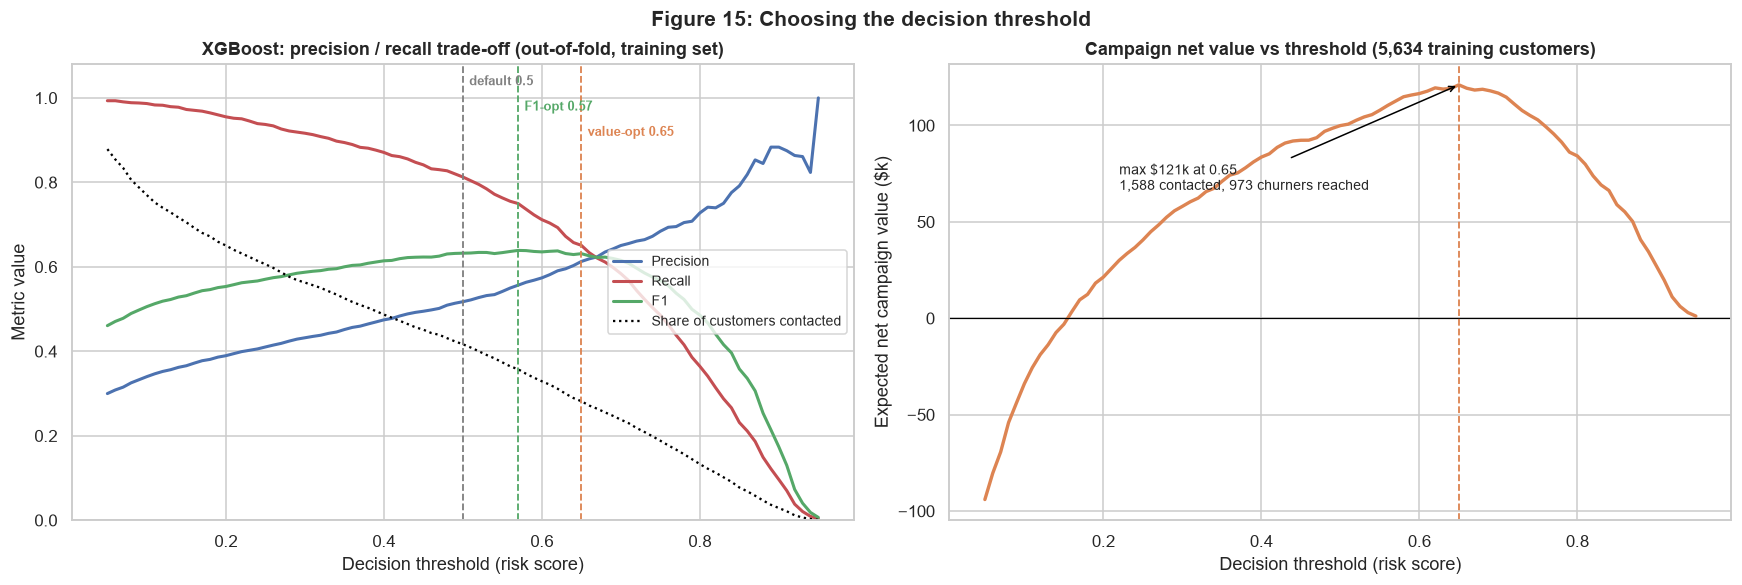

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
ax = axes[0]
ax.plot(sweep["threshold"], sweep["precision"], lw=2, color="#4C72B0", label="Precision")
ax.plot(sweep["threshold"], sweep["recall"], lw=2, color=CHURN_COLOR, label="Recall")
ax.plot(sweep["threshold"], sweep["f1"], lw=2, color="#55A868", label="F1")
ax.plot(sweep["threshold"], sweep["flagged_share"], lw=1.5, ls=":", color="black", label="Share of customers contacted")
for t, lbl, c, ytxt in [(0.5, "default 0.5", "grey", 1.03), (t_f1, f"F1-opt {t_f1:.2f}", "#55A868", 0.97),
                        (t_value, f"value-opt {t_value:.2f}", "#DD8452", 0.91)]:
    ax.axvline(t, ls="--", color=c, lw=1.2)
    ax.text(t + 0.008, ytxt, lbl, color=c, fontsize=8.5, fontweight="bold")
ax.set(xlabel="Decision threshold (risk score)", ylabel="Metric value", ylim=(0, 1.08),
       title=f"{FINAL_MODEL_NAME}: precision / recall trade-off (out-of-fold, training set)")
ax.legend(fontsize=9, loc="center right")

ax = axes[1]
ax.plot(sweep["threshold"], sweep["net_value"] / 1000, lw=2.2, color="#DD8452")
ax.axhline(0, color="black", lw=0.8)
ax.axvline(t_value, ls="--", color="#DD8452", lw=1.2)
best = sweep.loc[sweep["net_value"].idxmax()]
ax.annotate(f"max ${best['net_value'] / 1000:,.0f}k at {t_value:.2f}\n{int(best['contacted']):,} contacted, "
            f"{int(best['churners_caught']):,} churners reached",
            xy=(t_value, best["net_value"] / 1000), xytext=(0.22, best["net_value"] / 1000 * 0.55),
            arrowprops=dict(arrowstyle="->", color="black"), fontsize=9)
ax.set(xlabel="Decision threshold (risk score)", ylabel="Expected net campaign value ($k)",
       title=f"Campaign net value vs threshold ({len(y_train):,} training customers)")
fig.tight_layout()
finish_fig(fig, "threshold_selection", "Choosing the decision threshold")

In [35]:
DECISION_THRESHOLD = round(float(t_value), 2)
final_test_proba = test_proba[FINAL_MODEL_NAME]
mc_test = X_test["MonthlyCharges"].to_numpy()

final_metrics = ev.classification_metrics(y_test, final_test_proba, DECISION_THRESHOLD)
print(f"{FINAL_MODEL_NAME} on the TEST set at threshold {DECISION_THRESHOLD}:")
print("  " + " | ".join(f"{k} {v:.3f}" for k, v in final_metrics.items()))

# Compare the model-driven campaign with simple alternatives on the same test customers.
model_campaign = ev.campaign_value(y_test, final_test_proba, mc_test, DECISION_THRESHOLD)
everyone = ev.campaign_value(y_test, np.ones(len(y_test)), mc_test, 0.5)
n_contact = model_campaign["contacted"]
# Random targeting with the same budget: expected outcome of contacting n_contact customers at random.
rand_caught = n_contact * y_test.mean()
rand_saved = ev.SAVE_RATE * ev.VALUE_HORIZON_MONTHS * mc_test[y_test.to_numpy() == 1].mean() * rand_caught
strategies = pd.DataFrame([
    {"strategy": "No campaign", "contacted": 0, "churners_caught": 0, "net_value": 0.0},
    {"strategy": "Contact everyone", **{k: everyone[k] for k in ("contacted", "churners_caught", "net_value")}},
    {"strategy": f"Random {n_contact:,} customers (same budget)", "contacted": n_contact,
     "churners_caught": round(rand_caught), "net_value": rand_saved - ev.OFFER_COST * n_contact},
    {"strategy": f"Model-targeted (score >= {DECISION_THRESHOLD})",
     **{k: model_campaign[k] for k in ("contacted", "churners_caught", "net_value")}},
]).set_index("strategy")
strategies["share_of_churners_caught"] = (strategies["churners_caught"] / y_test.sum()).map("{:.0%}".format)
strategies["net_value"] = strategies["net_value"].map("${:,.0f}".format)
strategies

XGBoost on the TEST set at threshold 0.65:
  roc_auc 0.846 | pr_auc 0.663 | precision 0.591 | recall 0.658 | f1 0.623 | accuracy 0.789 | flagged_share 0.295


,contacted,churners_caught,net_value,share_of_churners_caught
strategy,,,,
No campaign,0,0,$0,0%
Contact everyone,1409,374,"$-42,926",100%
Random 416 customers (same budget),416,110,"$-12,674",29%
Model-targeted (score >= 0.65),416,246,"$26,344",66%


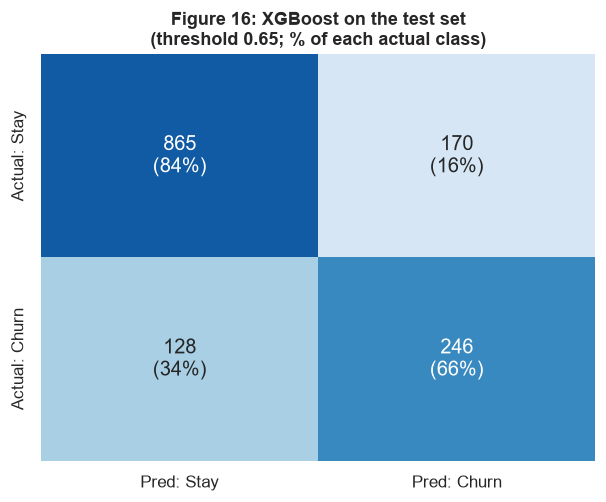

In [36]:
fig, ax = plt.subplots(figsize=(6.5, 4.8))
cm = ev.confusion_frame(y_test, (final_test_proba >= DECISION_THRESHOLD).astype(int))
row_pct = cm.div(cm.sum(axis=1), axis=0)
labels = np.array([[f"{n:,}\n({p:.0%})" for n, p in zip(cr, pr)] for cr, pr in zip(cm.values, row_pct.values)])
sns.heatmap(row_pct, annot=labels, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax, annot_kws={"fontsize": 13})
ax.set_ylabel("")
finish_fig(fig, "final_confusion_matrix",
           f"{FINAL_MODEL_NAME} on the test set\n(threshold {DECISION_THRESHOLD}; % of each actual class)", ax)

**Figures 15 & 16: the business operating point**

- On the training data (out-of-fold), net campaign value **peaks at a threshold of 0.65** (≈ \$121k across 5,634 customers). The **F1-optimal threshold is 0.57**, and the default 0.5 leaves about \$21k on the table.
- **The optimum is flat between about 0.60 and 0.70** (all within ~4% of the peak), so the recommendation does not depend on a knife-edge choice. Below about 0.15 the campaign *loses* money because offers go to too many loyal customers.
- Moving from 0.5 to 0.65 trades recall for precision: **we contact about a third fewer customers, and roughly 6 in 10 of them (instead of 5 in 10) really are churners.**

**Applied unchanged to the untouched test set (1,409 customers):**

| Strategy | Customers contacted | Churners reached | Net value |
|---|---|---|---|
| No campaign | 0 | 0 | \$0 |
| Contact everyone | 1,409 | 374 (100%) | **−\$42,926** |
| Random 416 customers (same budget) | 416 | ~110 (29%) | **−\$12,674** |
| **Model-targeted (score ≥ 0.65)** | **416** | **246 (66%)** | **+\$26,344** |

**With the same budget, the model reaches 2.2x as many churners as random targeting** and turns a loss-making campaign into a profitable one. At threshold 0.65 the test-set precision is 59% and recall 66% (Figure 16), close to the out-of-fold estimate, so the threshold choice generalises. Scaled to the full 7,043-customer base, the same policy suggests roughly **\$130k of net value per campaign cycle** *under the stated assumptions*. With real offer costs and save rates, the same code re-derives the threshold.

In [37]:
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)
artifact = {
    "pipeline": final_pipeline,
    "model_name": FINAL_MODEL_NAME,
    "decision_threshold": DECISION_THRESHOLD,
    "best_params": searches[FINAL_MODEL_NAME].best_params_,
    "cv_roc_auc": float(tuned_summary.loc[FINAL_MODEL_NAME, "roc_auc_mean"]),
    "test_roc_auc": float(test_results.loc[FINAL_MODEL_NAME, "test_roc_auc"]),
    "feature_columns": list(X_train.columns),
}
joblib.dump(artifact, MODEL_DIR / "connecttel_churn_model.joblib")

# Round-trip check: the saved pipeline reproduces the in-memory predictions.
reloaded = joblib.load(MODEL_DIR / "connecttel_churn_model.joblib")
assert np.allclose(reloaded["pipeline"].predict_proba(X_test)[:, 1], final_test_proba)
print(f"Saved {FINAL_MODEL_NAME} pipeline + threshold {DECISION_THRESHOLD} -> models/connecttel_churn_model.joblib")

Saved XGBoost pipeline + threshold 0.65 -> models/connecttel_churn_model.joblib


## Phase 3 Summary

1. **Gradient boosting (XGBoost, LightGBM) was added and all four models were tuned** with GridSearchCV over 194 hyperparameter combinations × 5 folds (970 model fits).
2. **Tuning mostly cured overfitting.** The best settings are deliberately *simple* models (depth-2 boosted trees, depth-6 forest with large leaves).
3. **All models plateau at AUC ≈ 0.85**, the information ceiling of this dataset. **XGBoost was selected** on cross-validated AUC (0.850). **Test AUC is 0.846 [0.824-0.867]**, confirming it generalises.
4. **The decision threshold was set by business value, not by default.** At 0.65 the model contacts 30% of customers, reaches 66% of churners with 59% precision, and **outperforms both "contact everyone" and random targeting** on unseen data.
5. The final pipeline and threshold are saved to `models/connecttel_churn_model.joblib`.

**Next (Phase 4):** SHAP analysis of the XGBoost model (global drivers, dependence plots, individual customer explanations), answering *"Is the month-to-month contract or the high monthly charge the bigger churn driver?"*, and the Business Insight Report.

## 9. Model Interpretation with SHAP

A model that flags customers without saying *why* gives the retention team nothing to act on. **SHAP (SHapley Additive exPlanations)** splits each individual prediction into a contribution from every feature, using Shapley values from cooperative game theory:

$$\text{model output for a customer} = \text{baseline (average output)} + \sum_{\text{features}} \text{SHAP value of that feature}$$

- A **positive** SHAP value pushes that customer *toward churn*, and a **negative** value pushes them toward staying.
- Values are in the model's raw output units, **log-odds**. A SHAP value of +0.7 multiplies the churn odds by about e^0.7 ≈ 2.
- We use `TreeExplainer`, which computes **exact** SHAP values for tree ensembles (no sampling approximation).
- Explanations are computed for the **1,409 test customers**, whom the model never saw during training.

**Grouping one-hot columns.** The model sees `Contract` as three 0/1 columns. SHAP values are additive, so we can **sum the columns back into their original feature** to get the total effect of "Contract" for each customer. This is essential for the brief's question: Contract vs. monthly charge.

In [38]:
import matplotlib
import shap

preprocess = final_pipeline.named_steps["preprocess"]
xgb_model = final_pipeline.named_steps["model"]
encoded_names = preprocess.get_feature_names_out()
X_test_enc = pd.DataFrame(preprocess.transform(X_test), columns=encoded_names, index=X_test.index)

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer(X_test_enc)

# Additivity check: baseline + sum of SHAP values reproduces the model's raw (log-odds) output exactly.
margin = xgb_model.predict(X_test_enc.to_numpy(), output_margin=True)
assert np.allclose(shap_values.values.sum(axis=1) + shap_values.base_values, margin, atol=1e-4)

# For plots, show numeric features in their original units (e.g. tenure in months) instead of z-scores.
display_data = X_test_enc.copy()
display_data[numeric_features] = X_test[numeric_features].to_numpy()
shap_exp = shap.Explanation(values=shap_values.values, base_values=shap_values.base_values,
                            data=display_data.to_numpy(), feature_names=list(encoded_names))

# Map every encoded column back to its original feature, then sum SHAP values within each feature.
onehot = preprocess.named_transformers_["cat"]
feature_of = {c: c for c in numeric_features}
for col, cats in zip(categorical_features, onehot.categories_):
    feature_of.update({f"{col}_{v}": col for v in cats})
shap_grouped = (pd.DataFrame(shap_values.values, columns=encoded_names, index=X_test.index)
                  .T.groupby(feature_of).sum().T)

print(f"SHAP values: {shap_values.values.shape[0]:,} customers x {shap_values.values.shape[1]} encoded features "
      f"-> {shap_grouped.shape[1]} original features")
print(f"Baseline (average model output): {shap_values.base_values[0]:+.3f} log-odds")

SHAP values: 1,409 customers x 58 encoded features -> 25 original features
Baseline (average model output): +0.007 log-odds


### 9.1 Global view: what drives churn across all customers?

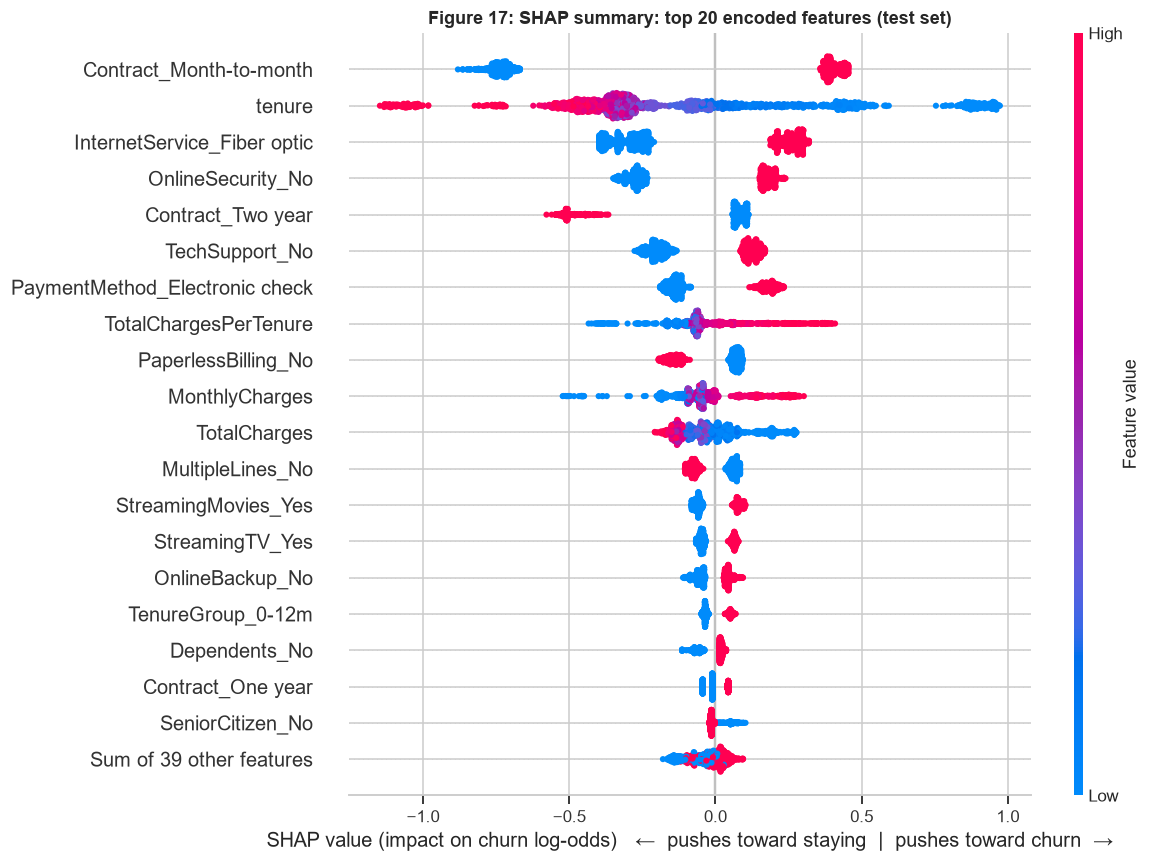

In [39]:
fig, ax = plt.subplots(figsize=(10, 9))
shap.plots.beeswarm(shap_exp, max_display=20, ax=ax, show=False, plot_size=None)
ax.set_xlabel("SHAP value (impact on churn log-odds)   ←  pushes toward staying  |  pushes toward churn  →")
finish_fig(fig, "shap_summary_beeswarm", "SHAP summary: top 20 encoded features (test set)", ax)

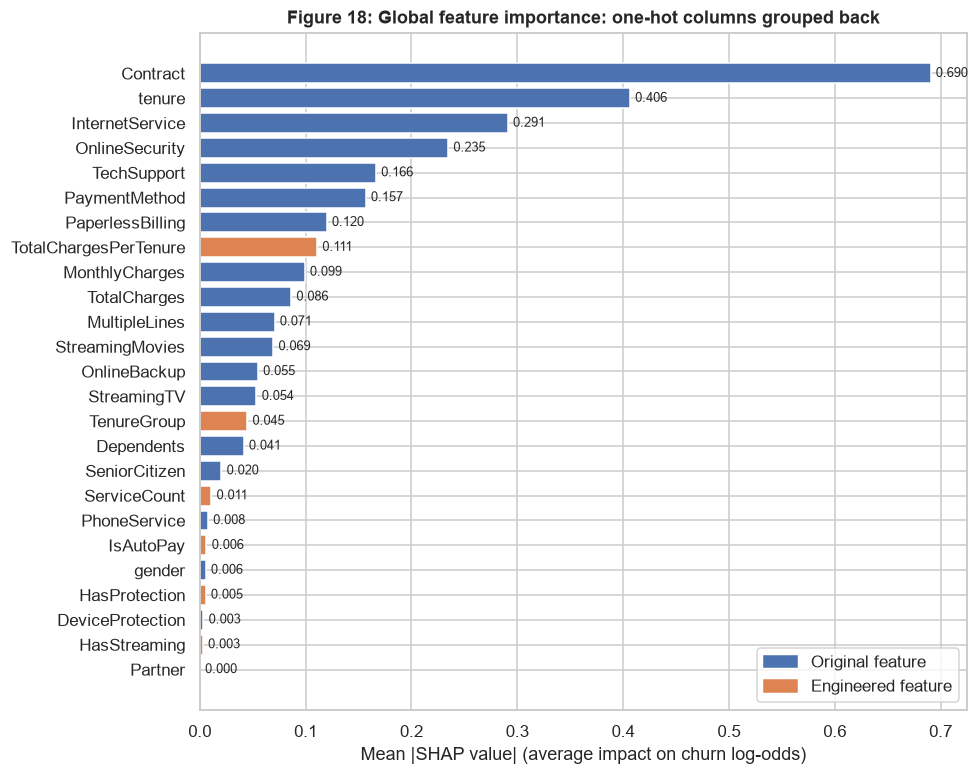

Contract                 25.0%
tenure                   14.7%
InternetService          10.5%
OnlineSecurity            8.5%
TechSupport               6.0%
PaymentMethod             5.7%
PaperlessBilling          4.3%
TotalChargesPerTenure     4.0%
MonthlyCharges            3.6%
TotalCharges              3.1%
Name: share of total impact, dtype: str

In [40]:
grouped_importance = shap_grouped.abs().mean().sort_values()
engineered = set(dp.ENGINEERED_FEATURES)

fig, ax = plt.subplots(figsize=(9, 8))
colors = ["#DD8452" if f in engineered else "#4C72B0" for f in grouped_importance.index]
ax.barh(grouped_importance.index, grouped_importance.values, color=colors)
for yi, v in enumerate(grouped_importance.values):
    ax.text(v + 0.005, yi, f"{v:.3f}", va="center", fontsize=8.5)
ax.set_xlabel("Mean |SHAP value| (average impact on churn log-odds)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="#4C72B0"), plt.Rectangle((0, 0), 1, 1, color="#DD8452")],
          labels=["Original feature", "Engineered feature"], loc="lower right")
finish_fig(fig, "shap_global_importance_grouped", "Global feature importance: one-hot columns grouped back", ax)

(grouped_importance.sort_values(ascending=False) / grouped_importance.sum()).head(10).map("{:.1%}".format).rename("share of total impact")

**Figures 17 & 18. What drives churn**

- **Contract type is the single largest driver, with 25% of the model's total explanatory impact.** Together with **tenure (15%)** it accounts for about 40%. *How committed* a customer is, and *for how long* they have stayed, matter more than anything else.
- Next come **Internet service (11%)**, **Online Security (8.5%)**, **Tech Support (6%)** and **Payment method (6%)**. These are the same drivers Phase 1 found, now confirmed *after* the model controls for all other features at once.
- **The beeswarm shows the direction of each effect.** Short tenure (blue dots on the `tenure` row) pushes strongly toward churn and long tenure pushes strongly away. Month-to-month, fiber optic, no security, no tech support and electronic check (red dots, right side) all push risk *up*.
- **All price features together (`TotalChargesPerTenure` 4.0%, `MonthlyCharges` 3.6%, `TotalCharges` 3.1%) are only mid-table.** The next section looks at this in detail.
- **`Partner` receives zero attribution.** The partner effect found in Phase 1 (H2) is real as a raw association, but **once tenure, contract and dependents are known, having a partner adds no information**: partnered customers simply tend to stay longer and sign longer contracts. A model-based check like this is important, because a retention campaign aimed at "single customers" would be targeting a proxy, not a cause.
- **Engineered features (orange):** XGBoost already learns non-linear shapes and interactions from the raw columns, so `ServiceCount`, `HasProtection`, `IsAutoPay` and `HasStreaming` add little on top. `TotalChargesPerTenure` ranks highest, but only because it duplicates `MonthlyCharges`. The engineered features were more useful for *understanding* the data (Phase 1) than for prediction.

### 9.2 The key question: is it the Month-to-Month contract or the high Monthly Charge?

The brief asks: *"Is the Month-to-Month contract the biggest driver of churn, or is it the high Monthly Charge?"*

Because `TotalChargesPerTenure` is effectively a copy of `MonthlyCharges` (§7.2), the model can split the "price" signal between the two. To compare fairly, we also build a **"Monthly price" group = MonthlyCharges + TotalChargesPerTenure** (summing SHAP values per customer), and an even broader **"All charges" group** that adds TotalCharges.

In [41]:
price_group = shap_grouped["MonthlyCharges"] + shap_grouped["TotalChargesPerTenure"]
all_charges = price_group + shap_grouped["TotalCharges"]
contract_shap = shap_grouped["Contract"]

head_to_head = pd.DataFrame({
    "mean |SHAP|": [contract_shap.abs().mean(), shap_grouped["MonthlyCharges"].abs().mean(),
                    price_group.abs().mean(), all_charges.abs().mean()],
    "share of customers where Contract has the larger effect": [
        np.nan, (contract_shap.abs() > shap_grouped["MonthlyCharges"].abs()).mean(),
        (contract_shap.abs() > price_group.abs()).mean(), (contract_shap.abs() > all_charges.abs()).mean()],
}, index=["Contract", "MonthlyCharges alone", "Monthly price (MonthlyCharges + TotalChargesPerTenure)",
          "All charges (+ TotalCharges)"])
head_to_head["vs Contract"] = head_to_head["mean |SHAP|"].iloc[0] / head_to_head["mean |SHAP|"]
head_to_head.round(3)

,mean |SHAP|,share of customers where Contract has the larger effect,vs Contract
Contract,0.690,NaN,1.000
MonthlyCharges alone,0.099,1.000,6.972
Monthly price (MonthlyCharges + TotalChargesPerTenure),0.208,0.972,3.315
All charges (+ TotalCharges),0.209,0.976,3.300


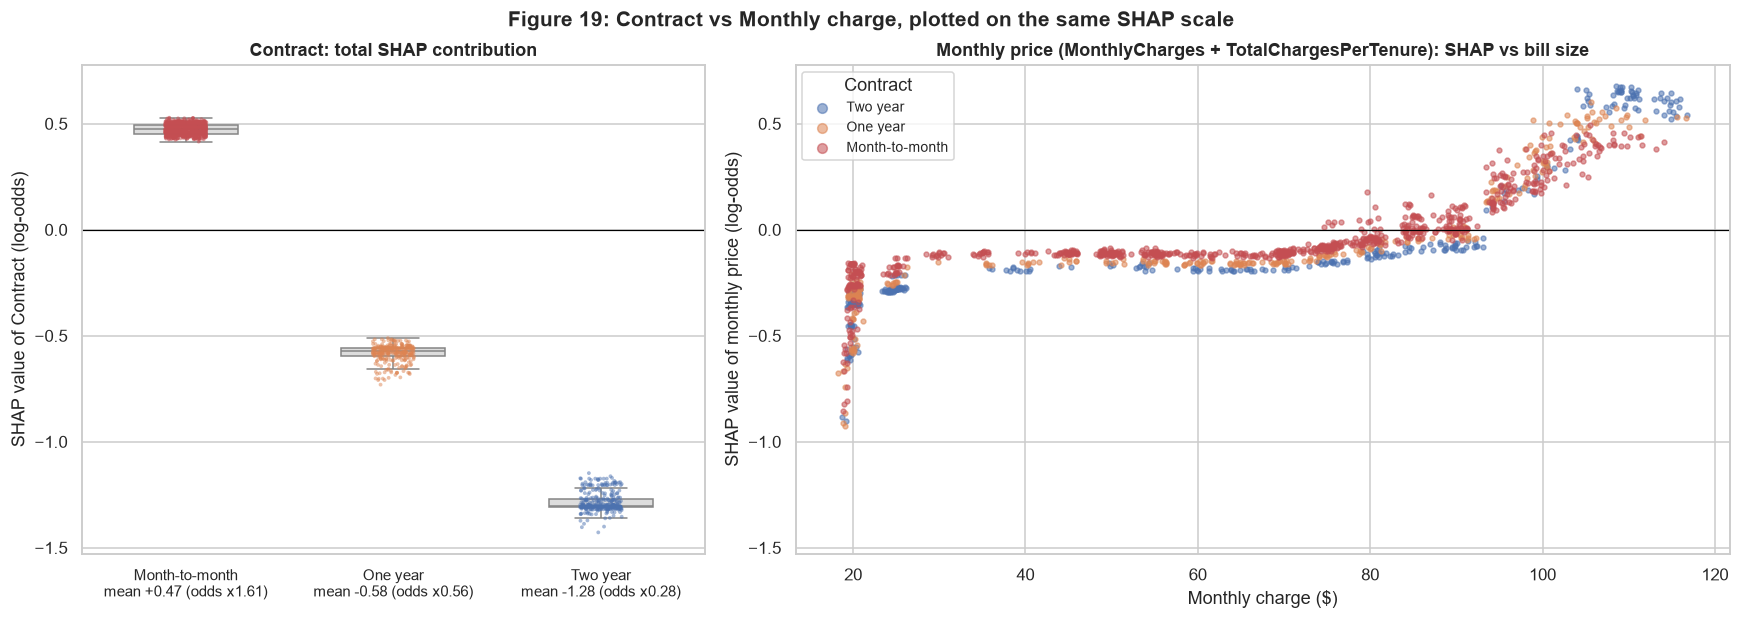

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1, 1.5]})

contract_levels = ["Month-to-month", "One year", "Two year"]
contract_df = pd.DataFrame({"Contract": X_test["Contract"].values, "SHAP": contract_shap.values})
sns.boxplot(data=contract_df, x="Contract", y="SHAP", order=contract_levels, ax=axes[0], color="#DDDDDD",
            showfliers=False, width=0.5)
sns.stripplot(data=contract_df, x="Contract", y="SHAP", order=contract_levels, ax=axes[0], size=2.5, alpha=0.5,
              hue="Contract", palette={"Month-to-month": CHURN_COLOR, "One year": "#DD8452", "Two year": STAY_COLOR},
              legend=False)
axes[0].axhline(0, color="black", lw=0.8)
contract_means = contract_df.groupby("Contract")["SHAP"].mean()
axes[0].set_xticks(range(3), [f"{lvl}\nmean {contract_means[lvl]:+.2f} (odds x{np.exp(contract_means[lvl]):.2f})"
                              for lvl in contract_levels], fontsize=9.5)
axes[0].set(ylabel="SHAP value of Contract (log-odds)", xlabel="", title="Contract: total SHAP contribution")

price_df = pd.DataFrame({"MonthlyCharges": X_test["MonthlyCharges"].values, "SHAP": price_group.values,
                         "Contract": X_test["Contract"].values})
for lvl, c in [("Two year", STAY_COLOR), ("One year", "#DD8452"), ("Month-to-month", CHURN_COLOR)]:
    sub = price_df[price_df["Contract"] == lvl]
    axes[1].scatter(sub["MonthlyCharges"], sub["SHAP"], s=10, alpha=0.55, color=c, label=lvl)
axes[1].axhline(0, color="black", lw=0.8)
# Same y-scale on both panels so the magnitudes can be compared directly.
lo = min(contract_shap.min(), price_group.min()) - 0.1
hi = max(contract_shap.max(), price_group.max()) + 0.1
for ax in axes:
    ax.set_ylim(lo, hi)
axes[1].set(xlabel="Monthly charge ($)", ylabel="SHAP value of monthly price (log-odds)",
            title="Monthly price (MonthlyCharges + TotalChargesPerTenure): SHAP vs bill size")
axes[1].legend(title="Contract", fontsize=9, markerscale=2)
fig.tight_layout()
finish_fig(fig, "contract_vs_monthly_charge", "Contract vs Monthly charge, plotted on the same SHAP scale")

**Figure 19. Answer: the Month-to-Month contract is the bigger driver, by a wide margin**

| Comparison | Mean \|SHAP\| | Contract is ... larger | Customers where Contract dominates |
|---|---|---|---|
| **Contract** | **0.690** | - | - |
| MonthlyCharges alone | 0.099 | **7.0x** | 100% |
| Monthly price (MonthlyCharges + TotalChargesPerTenure) | 0.208 | **3.3x** | 97% |
| All charges (+ TotalCharges) | 0.209 | **3.3x** | 98% |

- **Contract moves every customer's risk substantially.** Month-to-month adds **+0.47** log-odds (odds **x1.61**), a one-year contract subtracts 0.58 (x0.56), and a two-year contract subtracts 1.28 (x0.28). The swing from month-to-month to two-year is about **1.75 log-odds, a ~5.8x difference in churn odds**.
- **Price matters only at the extremes.** The right panel shows the price effect is **flat and slightly protective between about \$25 and \$75**, hovers around zero between \$80 and \$90, turns clearly positive only **above about \$90**, and reaches about +0.5 to +0.6 for bills above \$100. The very cheapest bills (around \$20, mostly phone-only customers) are strongly protective.
- **Even the most expensive customers get less risk from price than every month-to-month customer gets from the contract.** At every bill level, month-to-month customers (red) sit slightly above term-contract customers, but the price curve has the same shape for all contract types.

> **Conclusion:** the Month-to-Month contract is the biggest driver of churn. A high monthly charge is a **secondary** risk factor that only applies to the top price tier (above about \$90, mostly fiber customers). This matters for strategy: **a blanket price cut would address the smaller problem. Locking customers into longer contracts addresses the bigger one.**

### 9.3 Dependence plots: how each driver behaves

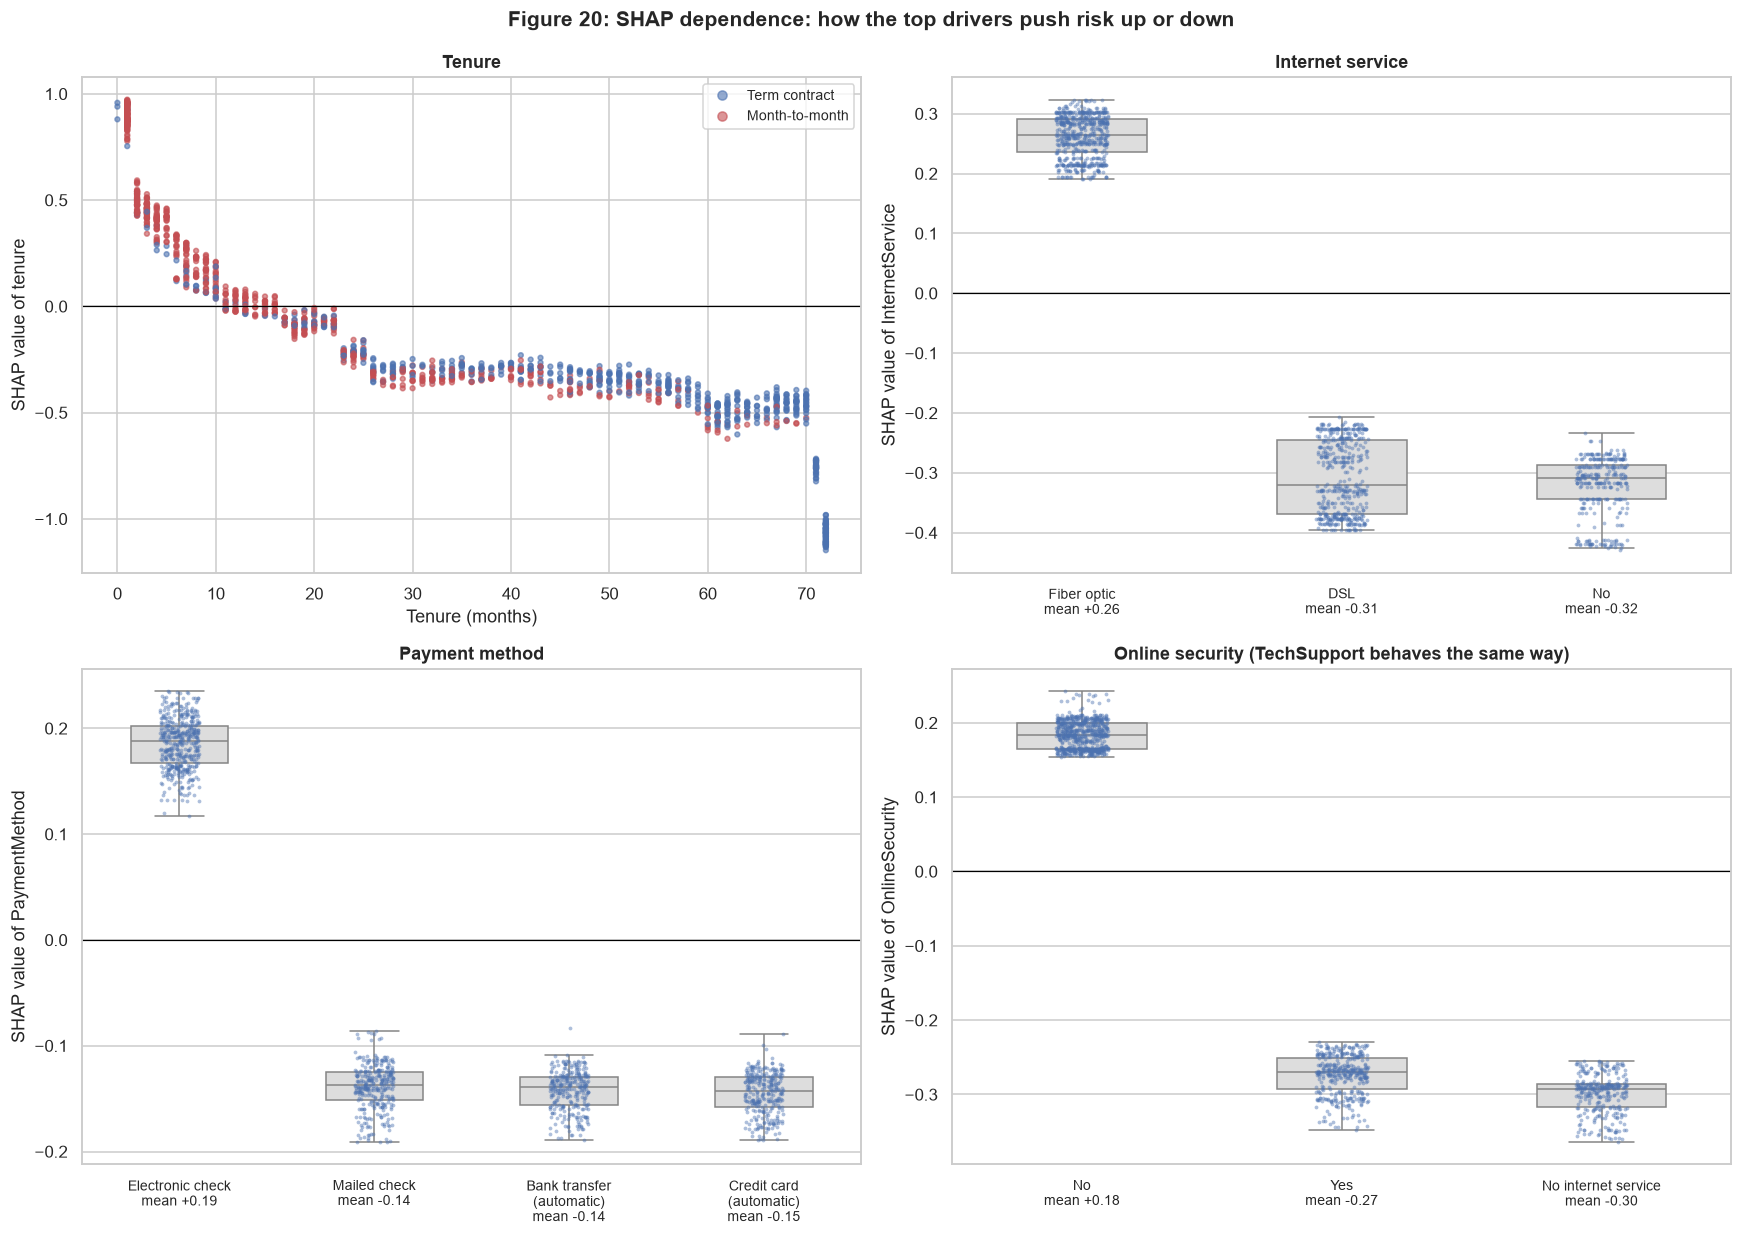

In [43]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

ax = axes[0, 0]
sc = ax.scatter(X_test["tenure"], shap_grouped["tenure"], c=(X_test["Contract"] == "Month-to-month").astype(int),
                cmap=matplotlib.colors.ListedColormap([STAY_COLOR, CHURN_COLOR]), s=10, alpha=0.6)
ax.axhline(0, color="black", lw=0.8)
ax.set(xlabel="Tenure (months)", ylabel="SHAP value of tenure", title="Tenure")
ax.legend(handles=sc.legend_elements()[0], labels=["Term contract", "Month-to-month"], fontsize=9)

def level_strip(ax, feature, order=None, title=None):
    d = pd.DataFrame({"level": X_test[feature].values, "SHAP": shap_grouped[feature].values})
    order = order or d.groupby("level")["SHAP"].mean().sort_values(ascending=False).index.tolist()
    sns.boxplot(data=d, x="level", y="SHAP", order=order, ax=ax, color="#DDDDDD", showfliers=False, width=0.5)
    sns.stripplot(data=d, x="level", y="SHAP", order=order, ax=ax, size=2.5, alpha=0.45, color="#4C72B0")
    ax.axhline(0, color="black", lw=0.8)
    means = d.groupby("level")["SHAP"].mean()
    ax.set_xticks(range(len(order)), [f"{lvl.replace(' (', chr(10) + '(')}\nmean {means[lvl]:+.2f}" for lvl in order],
                  fontsize=9)
    ax.set(xlabel="", ylabel=f"SHAP value of {feature}", title=title or feature)

level_strip(axes[0, 1], "InternetService", title="Internet service")
level_strip(axes[1, 0], "PaymentMethod", title="Payment method")
level_strip(axes[1, 1], "OnlineSecurity", title="Online security (TechSupport behaves the same way)")
fig.tight_layout()
finish_fig(fig, "shap_dependence", "SHAP dependence: how the top drivers push risk up or down")

**Figure 20. How each driver behaves**
- **Tenure:** risk is highest in the first months (+0.9 at 1 month), falls steeply through the **first year**, crosses zero at about **12 months**, then keeps declining slowly. Customers at the 72-month maximum get a strong loyalty bonus (−1.0). **The first year is where retention effort pays off most.**
- **Internet service:** fiber optic **+0.26** vs DSL **−0.31**, a gap of about 0.57 log-odds (**~1.8x the churn odds**), *after* accounting for price, contract and add-ons. Fiber customers are not leaving only because fiber costs more. Something about the fiber product experience itself is linked to churn.
- **Payment method:** electronic check is the only risky method (**+0.19**). Mailed check, bank transfer and credit card are all equally safe (≈ −0.14). The risk is specific to e-check, not to manual payment in general.
- **Online Security:** not having it adds **+0.18**, while having it subtracts 0.27, a ~1.6x odds gap. Tech Support behaves almost identically. These services make customers "sticky", which makes them a natural **retention offer**.

### 9.4 Individual explanations: why *this* customer?

SHAP also explains single predictions, which is what a retention agent needs before calling a customer. Below are the **highest-risk** and **lowest-risk** customers in the test set. Each waterfall starts from the baseline (average model output) and adds each feature's push until it reaches that customer's score.

In [44]:
test_risk = pd.Series(final_test_proba, index=X_test.index)
high_idx, low_idx = test_risk.idxmax(), test_risk.idxmin()
profile_cols = ["tenure", "Contract", "InternetService", "MonthlyCharges", "PaymentMethod", "OnlineSecurity",
                "TechSupport", "SeniorCitizen", "Dependents"]
profiles = X_test.loc[[high_idx, low_idx], profile_cols].copy()
profiles.insert(0, "risk score", test_risk[[high_idx, low_idx]].round(3).values)
profiles.insert(1, "actually churned", y_test[[high_idx, low_idx]].map({1: "Yes", 0: "No"}).values)
profiles.index = ["Highest-risk customer", "Lowest-risk customer"]
profiles.T

,Highest-risk customer,Lowest-risk customer
risk score,0.955,0.012
actually churned,Yes,No
tenure,1,72
Contract,Month-to-month,Two year
InternetService,Fiber optic,No
MonthlyCharges,95.100,19.950
PaymentMethod,Electronic check,Bank transfer (automatic)
OnlineSecurity,No,No internet service
TechSupport,No,No internet service
SeniorCitizen,Yes,No


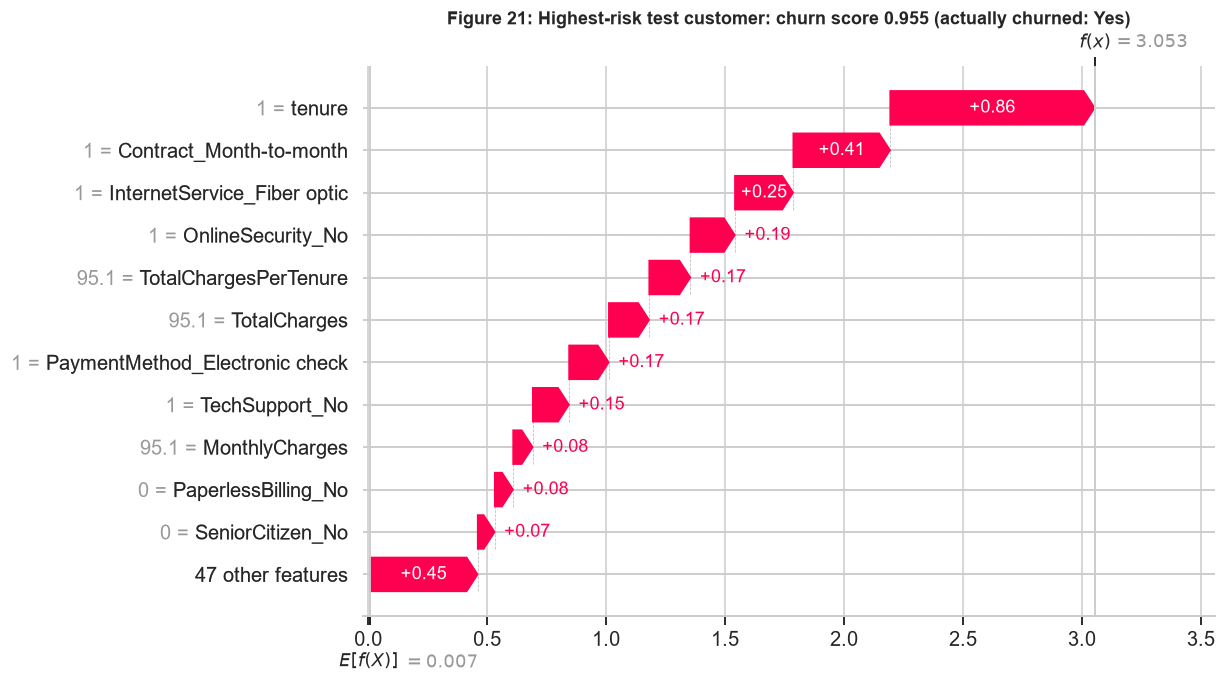

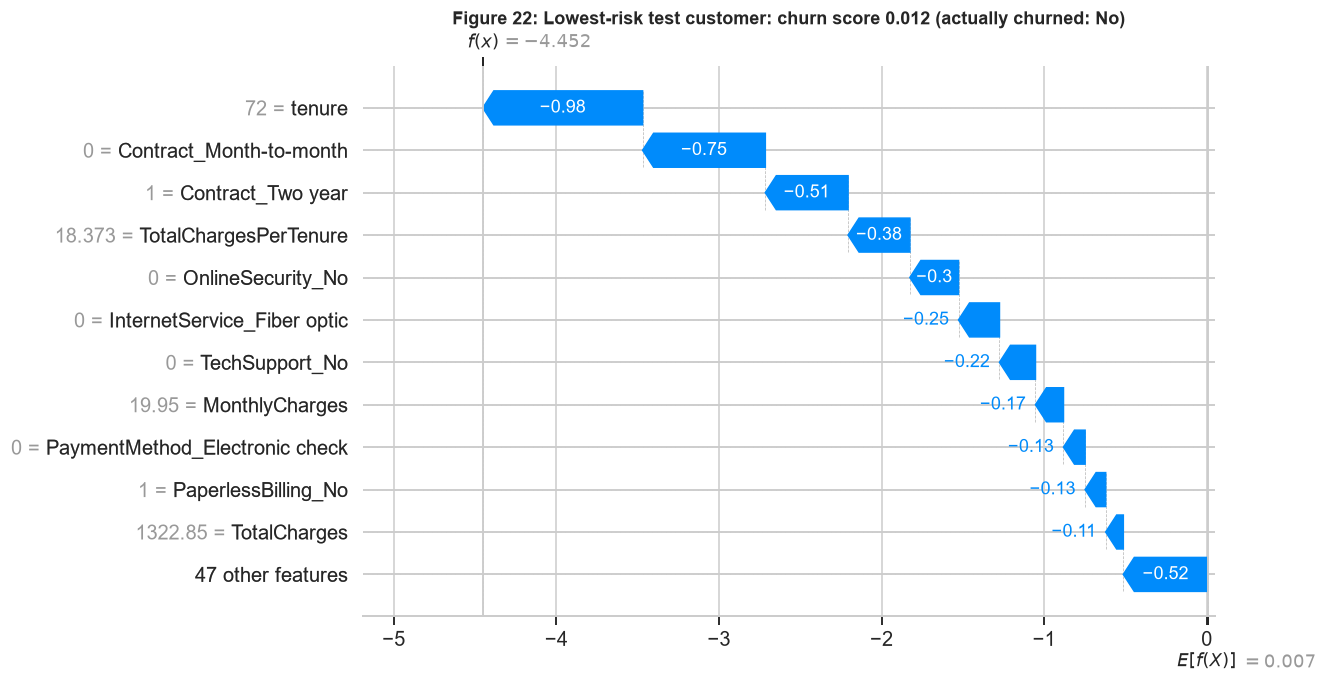

In [45]:
for idx, label, slug in [(high_idx, "Highest-risk", "waterfall_high_risk"), (low_idx, "Lowest-risk", "waterfall_low_risk")]:
    pos = X_test.index.get_loc(idx)
    shap.plots.waterfall(shap_exp[pos], max_display=12, show=False)
    fig = plt.gcf()
    fig.set_size_inches(10, 6.5)
    finish_fig(fig, slug, f"{label} test customer: churn score {test_risk[idx]:.3f} "
                          f"(actually churned: {'Yes' if y_test[idx] else 'No'})", fig.axes[0])

**Figures 21 & 22. Explaining individual customers**

- **Highest-risk customer (score 0.955, *did* churn):** a **1-month-old**, month-to-month, fiber optic customer paying \$95/month by electronic check, with no online security or tech support, and a senior citizen. **Tenure alone adds +0.86**, followed by month-to-month (+0.41), fiber (+0.25), no security (+0.19), e-check (+0.17) and the high monthly price (+0.17 via TotalChargesPerTenure, +0.08 via MonthlyCharges). Nearly every risk factor from this report applies at once.
- **Lowest-risk customer (score 0.012, stayed):** a **72-month** customer on a **two-year contract**, with no internet service, paying \$19.95/month by automatic bank transfer. Maximum tenure (−0.98) and the long contract (−0.75 and −0.51 from the two contract columns) dominate.

**Why this matters for operations:** a retention agent calling the first customer can see *the specific reasons* behind the score. The right offer here is a contract upgrade plus a free security/support bundle, not a generic discount.

## 10. Business Insight Report

### 10.1 Who is at risk right now?

We score **all 7,043 customers** without information leakage. Training customers get their out-of-fold scores from §8.5, so each was scored by a model that never saw them, and test customers get their test scores. We then apply the chosen threshold of 0.65.

In [46]:
risk_all = pd.concat([pd.Series(oof_proba, index=X_train.index),
                      pd.Series(final_test_proba, index=X_test.index)]).reindex(X.index)
base_df = X.assign(risk=risk_all, churned=y, flagged=risk_all >= DECISION_THRESHOLD)
flagged_df = base_df[base_df["flagged"]]

print(f"Customers flagged for retention : {len(flagged_df):,} of {len(base_df):,} ({len(flagged_df) / len(base_df):.1%})")
print(f"  of whom actually churned      : {flagged_df['churned'].mean():.1%} (precision)")
print(f"  share of all churners reached : {base_df.loc[base_df['churned'] == 1, 'flagged'].mean():.1%} (recall)")
print(f"Monthly revenue of flagged group: ${flagged_df['MonthlyCharges'].sum():,.0f} "
      f"(${flagged_df['MonthlyCharges'].sum() * 12:,.0f} per year)")
print(f"Avg bill flagged vs everyone    : ${flagged_df['MonthlyCharges'].mean():.2f} vs ${base_df['MonthlyCharges'].mean():.2f}")
print(f"Median tenure flagged           : {flagged_df['tenure'].median():.0f} months "
      f"(everyone: {base_df['tenure'].median():.0f})")

segments = (base_df.groupby(["Contract", "InternetService"])
            .agg(customers=("risk", "size"), actual_churn_rate=("churned", "mean"), mean_risk=("risk", "mean"),
                 flagged=("flagged", "sum"))
            .assign(share_of_flagged=lambda d: d["flagged"] / d["flagged"].sum())
            .sort_values("flagged", ascending=False))
segments.round(3)

Customers flagged for retention : 2,004 of 7,043 (28.5%)
  of whom actually churned      : 60.8% (precision)
  share of all churners reached : 65.2% (recall)
Monthly revenue of flagged group: $158,259 ($1,899,103 per year)
Avg bill flagged vs everyone    : $78.97 vs $64.76
Median tenure flagged           : 7 months (everyone: 29)


customers  actual_churn_rate  mean_risk  \
Contract       InternetService                                            
Month-to-month Fiber optic           2128              0.546      0.744   
               DSL                   1223              0.322      0.543   
               No                     524              0.189      0.351   
One year       Fiber optic            539              0.193      0.360   
               DSL                    570              0.093      0.177   
               No                     364              0.025      0.091   
Two year       DSL                    628              0.019      0.064   
               Fiber optic            429              0.072      0.168   
               No                     638              0.008      0.035   

                                flagged  share_of_flagged  
Contract       InternetService                             
Month-to-month Fiber optic         1630             0.813  
               DSL                  366             0.183  
               No                     4             0.002  
One year       Fiber optic            4             0.002  
               DSL                    0             0.000  
               No                     0             0.000  
Two year       DSL                    0             0.000  
               Fiber optic            0             0.000  
               No                     0             0.000

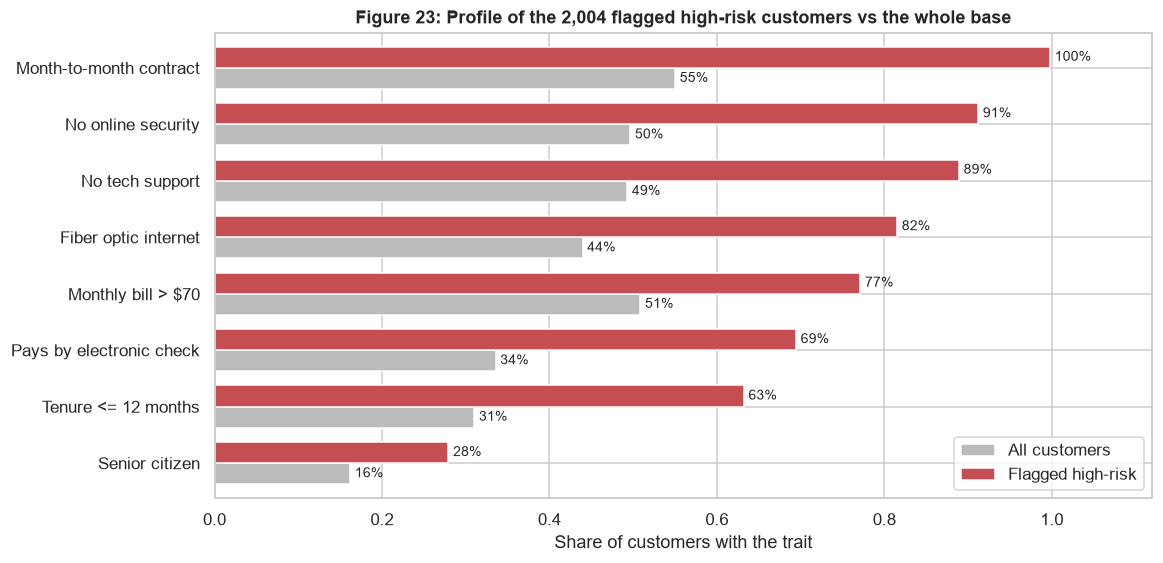

In [47]:
traits = {
    "Month-to-month contract": base_df["Contract"] == "Month-to-month",
    "Fiber optic internet": base_df["InternetService"] == "Fiber optic",
    "Tenure <= 12 months": base_df["TenureGroup"] == "0-12m",
    "Pays by electronic check": base_df["PaymentMethod"] == "Electronic check",
    "No online security": base_df["OnlineSecurity"] == "No",
    "No tech support": base_df["TechSupport"] == "No",
    "Senior citizen": base_df["SeniorCitizen"] == "Yes",
    "Monthly bill > $70": base_df["MonthlyCharges"] > 70,
}
trait_df = pd.DataFrame({"All customers": {k: v.mean() for k, v in traits.items()},
                         "Flagged high-risk": {k: v[base_df["flagged"]].mean() for k, v in traits.items()}})

fig, ax = plt.subplots(figsize=(11, 5.5))
trait_df.sort_values("Flagged high-risk").plot.barh(ax=ax, color=["#BBBBBB", CHURN_COLOR], width=0.75)
for container in ax.containers:
    ax.bar_label(container, labels=[f"{v:.0%}" for v in container.datavalues], padding=3, fontsize=9)
ax.set_xlim(0, 1.12)
ax.set_xlabel("Share of customers with the trait")
ax.legend(loc="lower right")
finish_fig(fig, "high_risk_profile", f"Profile of the {len(flagged_df):,} flagged high-risk customers vs the whole base", ax)

**Figure 23. Who the model flags**

The model flags **2,004 customers (28.5% of the base)**. **61%** of them really churned (precision), and they include **65% of all churners** (recall). These customers generate **\$158k of monthly revenue (≈ \$1.9M per year)**, and their average bill is \$79 against \$65 for the base.

The high-risk profile is very consistent:
- **Contract:** essentially **all (99.8%) are month-to-month**, vs 55% of the base.
- **Internet:** **81% are month-to-month *fiber* customers**, a single segment of 2,128 customers with a 55% actual churn rate. Month-to-month DSL makes up the remaining 18%.
- **Tenure:** 63% are in their **first year** (median tenure **7 months** vs 29 for the base).
- **Services:** **91% have no online security** and 89% no tech support (vs about 50% of the base).
- **Payment:** **69% pay by electronic check** (vs 34%).
- **Senior citizens** are over-represented (28% vs 16%).

### 10.2 Which retention levers move the needle? (model-based what-if analysis)

SHAP shows *what* drives risk. To estimate which **actionable** levers matter most, we re-score the test customers after changing one thing at a time, recomputing every engineered feature so the inputs stay consistent:

| Lever | Change simulated | Customers it applies to |
|---|---|---|
| **Contract conversion** | Month-to-month → One year | Month-to-month customers |
| **Free protection bundle** | Add Online Security + Tech Support (bill unchanged) | Fiber customers missing either service |
| **Auto-pay migration** | Electronic check → Credit card (automatic) | Electronic-check payers |

> ⚠️ **This shows the *model's* response, not a guaranteed causal effect.** For example, customers who choose annual contracts may differ in ways the data does not record. These estimates rank the levers for an **A/B-tested pilot**. They are not a promise of results.

In [48]:
levers = {
    "Contract conversion (M2M -> 1 year)": (
        X_test["Contract"] == "Month-to-month", {"Contract": {"Month-to-month": "One year"}}),
    "Free protection bundle (fiber)": (
        (X_test["InternetService"] == "Fiber optic") & ((X_test["OnlineSecurity"] == "No") | (X_test["TechSupport"] == "No")),
        {"OnlineSecurity": {"No": "Yes"}, "TechSupport": {"No": "Yes"}}),
    "Auto-pay migration (e-check -> card)": (
        X_test["PaymentMethod"] == "Electronic check", {"PaymentMethod": {"Electronic check": "Credit card (automatic)"}}),
}

lever_rows = []
for name, (mask, changes) in levers.items():
    mask = mask.to_numpy()
    new_risk = final_pipeline.predict_proba(dp.what_if(X_test, **changes))[:, 1]
    lever_rows.append({
        "lever": name, "customers targeted": int(mask.sum()),
        "mean risk before": final_test_proba[mask].mean(), "mean risk after": new_risk[mask].mean(),
        "flagged before": int((final_test_proba[mask] >= DECISION_THRESHOLD).sum()),
        "flagged after": int((new_risk[mask] >= DECISION_THRESHOLD).sum()),
    })
lever_df = pd.DataFrame(lever_rows).set_index("lever")
lever_df["high-risk customers removed"] = lever_df["flagged before"] - lever_df["flagged after"]
lever_df["% of flagged de-risked"] = (lever_df["high-risk customers removed"] / lever_df["flagged before"]).map("{:.0%}".format)
lever_df.round(3)

,customers targeted,mean risk before,mean risk after,flagged before,flagged after,high-risk customers removed,% of flagged de-risked
lever,,,,,,,
Contract conversion (M2M -> 1 year),773,0.629,0.403,413,94,319,77%
Free protection bundle (fiber),537,0.649,0.538,331,179,152,46%
Auto-pay migration (e-check -> card),474,0.629,0.565,278,211,67,24%


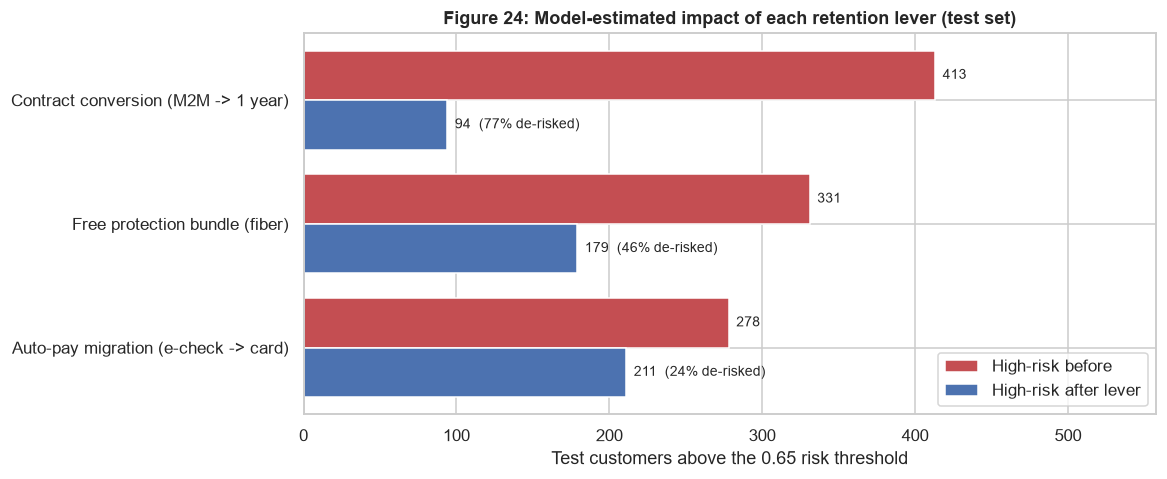

In [49]:
fig, ax = plt.subplots(figsize=(10, 4.5))
order = lever_df.sort_values("high-risk customers removed").index
y_pos = np.arange(len(order))
ax.barh(y_pos + 0.2, lever_df.loc[order, "flagged before"], height=0.4, color=CHURN_COLOR, label="High-risk before")
ax.barh(y_pos - 0.2, lever_df.loc[order, "flagged after"], height=0.4, color=STAY_COLOR, label="High-risk after lever")
for yi, name in enumerate(order):
    r = lever_df.loc[name]
    ax.text(r["flagged before"] + 5, yi + 0.2, f"{int(r['flagged before'])}", va="center", fontsize=9)
    ax.text(r["flagged after"] + 5, yi - 0.2, f"{int(r['flagged after'])}  ({r['% of flagged de-risked']} de-risked)",
            va="center", fontsize=9)
ax.set_yticks(y_pos, order)
ax.set_xlabel(f"Test customers above the {DECISION_THRESHOLD} risk threshold")
ax.set_xlim(0, lever_df["flagged before"].max() * 1.35)
ax.legend(loc="lower right")
finish_fig(fig, "retention_levers", "Model-estimated impact of each retention lever (test set)", ax)

**Figure 24. Lever effectiveness (model-estimated, test set)**

| Lever | Targeted | Mean risk before → after | High-risk customers removed |
|---|---|---|---|
| **Contract conversion** (M2M → 1 year) | 773 | 0.629 → **0.403** | 413 → 94 (**77%**) |
| **Free protection bundle** (fiber) | 537 | 0.649 → **0.538** | 331 → 179 (**46%**) |
| **Auto-pay migration** (e-check → card) | 474 | 0.629 → **0.565** | 278 → 211 (**24%**) |

**Contract conversion is by far the most powerful lever.** The protection bundle is a strong second and also addresses the fiber-experience problem. Auto-pay migration has a smaller effect but is very cheap to run. The levers target overlapping customers, so their effects should not be added together.

### 10.3 Recommendations

**The highest-risk group is clear.** *Fiber optic customers on month-to-month contracts in their first year*, typically paying \$80+ by electronic check without security or support add-ons. This group (2,128 customers, 55% churn rate) makes up **81% of everyone the model flags**.

| # | Recommendation | Target | Evidence |
|---|---|---|---|
| **1** | **Contract-conversion offer.** Offer a meaningful discount (e.g. 10-15% or one free month) for moving from month-to-month to a **1-year contract**. | Flagged month-to-month customers, starting with **fiber** (1,630 flagged) | Contract is the #1 driver (25% of impact, 3-7x price). The model estimates **77% of high-risk customers are de-risked** by a 1-year contract. |
| **2** | **"Fiber Peace-of-Mind" bundle.** Give Online Security + Tech Support **free for 6 months**, then at a reduced price. | Fiber customers missing either service | No security/support is the #4/#5 driver (+0.18 log-odds each). The model estimates **46% de-risked**. It also improves the fiber experience. |
| **3** | **First-year onboarding programme.** Proactive check-ins at months 1, 3 and 6, a welcome credit, and early resolution of setup issues. | All new customers, prioritised by risk score | Tenure is the #2 driver. 63% of flagged customers are in year one (median 7 months). |
| **4** | **Auto-pay migration incentive.** A small one-time credit (e.g. \$5-10) for switching from electronic check to automatic card or bank payment. | Electronic-check payers (69% of flagged) | E-check is the only risky payment method. The model estimates **24% de-risked** for a very low cost per customer. |
| **5** | **Investigate the fiber product.** Analyse outage and support-ticket data and price competitiveness against competitors, and run an NPS survey of fiber users. | Product and network teams | Fiber churns at ~1.8x the odds of DSL *even after controlling for price and contract*, which suggests a service-quality or value problem that discounts alone will not fix. |
| **6** | **Do not run blanket price cuts.** Reserve price concessions for the top tier (\$90+ bills) inside recommendations 1-2. | - | Price adds churn risk only above about \$90. Across the base its impact is 3x smaller than contract type. |

**Example (in the format of the brief):** *"The model indicates that Fiber Optic customers on month-to-month contracts, especially in their first year and paying by electronic check, are our highest-risk group: they churn at 55% and make up 81% of flagged customers. We recommend offering them a discounted 1-year contract bundled with free Online Security and Tech Support for six months. This addresses the two strongest controllable churn drivers at once."*

**Operationalising the model**
1. **Score all active customers monthly** with the saved pipeline (`models/connecttel_churn_model.joblib`) and contact those above the **0.65** threshold. In the test set this policy reached 66% of churners while contacting 30% of customers, and it was the only strategy with positive net value.
2. **Give agents the top 3 SHAP reasons** for each flagged customer, so each offer matches the customer's specific risk factors (contract, services, payment).
3. **Measure true impact with a randomised hold-out group.** Keep about 10% of flagged customers out of the campaign and compare their churn with the treated group. This turns the model-based estimates in §10.2 into measured causal effects, and gives the real offer cost and save rate needed to recalibrate the threshold.

## 11. Limitations & Next Steps

**Limitations**
- **Single snapshot, no time dimension.** We cannot see *when* customers churned or how their behaviour changed beforehand. A production model should predict "churn in the next 90 days" from monthly history.
- **Prediction ceiling (AUC ≈ 0.85).** Every model plateaued at the same level, so the remaining uncertainty lies in information the dataset does not contain: usage, network quality, support interactions, competitor offers.
- **What-if estimates are not causal.** The lever simulations (§10.2) show how the *model* responds. Customers who choose longer contracts may differ in unrecorded ways. Only a controlled experiment can measure true uplift.
- **Scores are not calibrated probabilities.** Class weighting shifts scores upward. If true probabilities are needed (e.g. for expected-revenue forecasts), add a calibration step (`CalibratedClassifierCV`).
- **Campaign economics are assumptions.** The \$100 offer cost and 30% save rate are illustrative. With real figures, the threshold should be re-derived in §8.5.
- **Fairness.** `SeniorCitizen` contributes to risk scores. Using age in *targeting* offers is generally acceptable, but it should be reviewed against company policy and regulation before deployment.

**Next steps**
1. Enrich the data with usage, billing history, support tickets and network-quality metrics to break through the 0.85 ceiling.
2. Move to **uplift modelling** after the first A/B test: predict *who will respond to an offer*, not just who will churn, and stop spending on "sure things" and "lost causes".
3. Add **probability calibration**, and **monitoring for data and performance drift**, with scheduled retraining.
4. Package scoring as a monthly batch job that feeds the CRM with risk scores and SHAP reasons.

---
*End of report.*